# 🏦 Credit Risk Prediction — Exploratory Data Analysis

**Dataset:** Give Me Some Credit (Kaggle) — `cs-training.csv`, 150,000 borrowers  
**Target:** `SeriousDlqin2yrs` — 0 = Good Borrower, 1 = Serious Delinquency (90+ days past due within 2 years)  
**Project:** AI Loan Underwriting Platform (capstone) — credit-risk module  
**Author:** Narendra Kalam

---

## 🏦 Business Problem

Lenders lose money when borrowers stop repaying. An underwriting system must decide — at the moment of application — whether to approve, review or decline a loan, and at what price, using only the information available today. A wrong **approval** creates a credit loss; a wrong **decline** loses a profitable customer.

**Key challenges:**
- Defaults are rare (~6.7%) — standard accuracy is misleading: predicting "Good" for everyone gives ~93% accuracy and catches zero defaulters
- ~20% of borrowers have no recorded income, and the missingness itself carries risk information
- The data contains system placeholder codes (96 / 98 in delinquency counters) and corrupt values (age = 0, utilisation above 50,000×)
- Credit decisions are regulated — the model must be **explainable** (adverse-action reason codes), monotonic where business logic demands, and **calibrated** (it outputs a Probability of Default, not just a rank)

**Goal:** Understand the data well enough to build a calibrated, explainable Probability-of-Default (PD) model — and feed it into a decision engine with APPROVE / REVIEW / DECLINE outputs — alongside the fraud-detection module of the capstone.

> ⚠️ **Leakage discipline:** Steps 3–6 are structural data-quality checks on the full file. The stratified 80/20 hold-out is carved out at the end of Step 5 (after de-duplication). From Step 7 onward every statistic (cap, median, bin edge, IV) is learned from the **training split only**.  
> 📝 Every number quoted in the Observation blocks is read from the executed outputs of this notebook (Kaggle `cs-training.csv`, seed 42). Re-run the notebook and re-check them if the data, the seed or the split changes.

---

## 📖 Data Dictionary

| Raw column | Short name | Meaning |
|---|---|---|
| `SeriousDlqin2yrs` | `default` | **Target** — 90+ days past due within 2 years (1 = bad) |
| `RevolvingUtilizationOfUnsecuredLines` | `revolving_util` | Card / credit-line balance ÷ total credit limit |
| `age` | `age` | Borrower age in years |
| `NumberOfTime30-59DaysPastDueNotWorse` | `past_due_30_59` | Times 30–59 days late (last 2 years) |
| `DebtRatio` | `debt_ratio` | Monthly debt payments ÷ monthly gross income |
| `MonthlyIncome` | `monthly_income` | Monthly income |
| `NumberOfOpenCreditLinesAndLoans` | `open_credit_lines` | Open loans + credit lines |
| `NumberOfTimes90DaysLate` | `late_90` | Times 90+ days late |
| `NumberRealEstateLoansOrLines` | `real_estate_loans` | Mortgage / real-estate loans |
| `NumberOfTime60-89DaysPastDueNotWorse` | `past_due_60_89` | Times 60–89 days late (last 2 years) |
| `NumberOfDependents` | `dependents` | Dependents excluding the borrower |

---

## 📌 Notebook Workflow

| Step | Topic |
|------|-------|
| 1 | Import libraries |
| 2 | Data loading and initial inspection |
| 3 | Dataset structure and data types |
| 4 | Missing values analysis |
| 5 | Duplicate detection and stratified hold-out |
| 6 | Statistical summary heatmap |
| 7 | Class imbalance analysis |
| 8 | Univariate distributions and skewness |
| 9 | Outliers and sentinel codes (96 / 98) |
| 10 | Age analysis |
| 11 | Revolving utilisation analysis |
| 12 | Delinquency history vs default |
| 13 | Debt ratio — the income-missing anomaly |
| 14 | Monthly income — decile risk profile |
| 15 | Credit lines, real-estate loans and dependents |
| 16 | Correlation matrix — raw vs sentinel-cleaned |
| 17 | Weight of Evidence and Information Value |
| 18 | Feature engineering validation |
| 19 | Multicollinearity check (VIF) |
| 20 | Class imbalance handling preview |
| 21 | Feature scaling preview |
| 22 | Key insights summary |

---

---
## Step 1 — Import Libraries
---
**Why:** All required libraries are imported upfront with explicit version printing so that results are reproducible. `scipy.stats` provides hypothesis tests (chi-square) to confirm visual patterns statistically, `statsmodels` provides the Variance Inflation Factor, and `imbalanced-learn` powers the SMOTE preview used to compare imbalance strategies.  

**Business insight:** In a regulated lending environment, every number in a model-risk report must be reproducible. Fixed seeds, pinned library versions and one shared helper cell make the EDA auditable.

In [25]:
import json
import warnings
warnings.filterwarnings("ignore")
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import statsmodels

from scipy import stats
from sklearn.preprocessing   import StandardScaler, PowerTransformer, MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model    import LogisticRegression
from sklearn.pipeline        import make_pipeline
from sklearn.metrics         import roc_auc_score, average_precision_score, brier_score_loss
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant

try:
    from imblearn.over_sampling import SMOTE
except ImportError:          # SMOTE preview (Step 20) is skipped gracefully if not installed
    SMOTE = None

# ── Plot style ────────────────────────────────────────────────
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams.update({
    "figure.dpi":       120,
    "figure.figsize":   (12, 5),
    "axes.titlesize":   13,
    "axes.titleweight": "bold",
    "axes.labelsize":   11,
    "axes.spines.top":  False,
    "axes.spines.right":False,
})

BAD_COLOR    = "#E74C3C"   # red   — default / high-risk
GOOD_COLOR   = "#2ECC71"   # green — good borrower / low-risk
ACCENT_COLOR = "#3498DB"   # blue  — neutral / highlight
WARN_COLOR   = "#F39C12"   # amber — borderline / review

print("✅ All libraries imported successfully")
print(f"   NumPy       : {np.__version__}")
print(f"   Pandas      : {pd.__version__}")
print(f"   Statsmodels : {statsmodels.__version__}")
print(f"   SMOTE       : {'available' if SMOTE is not None else 'not installed (Step 20 will skip it)'}")

✅ All libraries imported successfully
   NumPy       : 1.26.4
   Pandas      : 2.2.2
   Statsmodels : 0.15.0
   SMOTE       : available


In [26]:
# ── Configuration and reusable helpers ─────────────────────────
RANDOM_STATE = 42
PALETTE = {"good": GOOD_COLOR, "bad": BAD_COLOR, "neutral": "#7F8C8D"}
RAW_TARGET = "SeriousDlqin2yrs"
RENAME = {
    "SeriousDlqin2yrs": "default",
    "RevolvingUtilizationOfUnsecuredLines": "revolving_util",
    "age": "age",
    "NumberOfTime30-59DaysPastDueNotWorse": "past_due_30_59",
    "DebtRatio": "debt_ratio",
    "MonthlyIncome": "monthly_income",
    "NumberOfOpenCreditLinesAndLoans": "open_credit_lines",
    "NumberOfTimes90DaysLate": "late_90",
    "NumberRealEstateLoansOrLines": "real_estate_loans",
    "NumberOfTime60-89DaysPastDueNotWorse": "past_due_60_89",
    "NumberOfDependents": "dependents",
}
TARGET = "default"
DELINQ = ["past_due_30_59", "past_due_60_89", "late_90"]
FEATURES = ["revolving_util", "age", "past_due_30_59", "debt_ratio", "monthly_income",
            "open_credit_lines", "late_90", "real_estate_loans", "past_due_60_89", "dependents"]

DATA_CANDIDATES = [Path(r"D:\Data_Science_Capstone_Datasets\ai-loan-underwriting-platform\GiveMeSomeCredit\cs-training.csv"), Path("data/raw/cs-training.csv"), Path("../data/raw/cs-training.csv"),
                   Path("cs-training.csv"), Path("/kaggle/input/GiveMeSomeCredit/cs-training.csv")]
REPORT_DIR = Path("reports"); REPORT_DIR.mkdir(exist_ok=True)
BASE_RATE = None   # set in Step 2 after the train/hold-out split


# ---------- reusable helpers ----------
def mask_sentinels(d, cols=DELINQ, codes=(96, 98)):
    """Replace the 96/98 system codes in delinquency columns with NaN (kept in a copy)."""
    d = d.copy()
    for c in cols:
        d[c] = d[c].where(~d[c].isin(codes))
    return d


def rate_table(d, col, bins=None, q=None):
    """Default rate + volume per bucket (fixed bins or quantiles)."""
    s = d[col]
    grp = pd.qcut(s, q=q, duplicates="drop") if q else pd.cut(s, bins=bins, include_lowest=True)
    t = d.groupby(grp, observed=True)[TARGET].agg(default_rate="mean", customers="count")
    t["lift_vs_base"] = t["default_rate"] / BASE_RATE
    return t


def plot_rate(t, ax, title, xlabel):
    x = t.index.astype(str)
    ax.bar(x, t["default_rate"], color=PALETTE["bad"], alpha=0.85)
    ax.axhline(BASE_RATE, ls="--", c="k", lw=1, label=f"Base rate {BASE_RATE:.1%}")
    ax.yaxis.set_major_formatter(mticker.PercentFormatter(1.0))
    ax.set_title(title); ax.set_xlabel(xlabel); ax.set_ylabel("Default rate")
    ax.tick_params(axis="x", rotation=45)
    ax2 = ax.twinx(); ax2.plot(x, t["customers"], color=PALETTE["good"], marker="o", lw=1.5)
    ax2.set_ylabel("Customers", color=PALETTE["good"]); ax2.grid(False)
    ax2.spines["right"].set_visible(True)
    ax.legend(loc="upper left", fontsize=8)


def rate_by_value(d, col, cap):
    """Default rate for discrete counts, with a top-coded 'cap+' bucket."""
    s = d[col].clip(upper=cap)
    t = d.groupby(s)[TARGET].agg(default_rate="mean", customers="count")
    t.index = [f"{int(i)}" if i < cap else f"{cap}+" for i in t.index]
    return t

📌 **Observation:**

- All imports succeed in the capstone environment (NumPy 1.26.4, Pandas 2.2.2, Statsmodels 0.15.0) and `imbalanced-learn` is installed, so the SMOTE comparison in Step 20 can run.
- One configuration cell now holds the seed, the column-rename map, the colour palette and four helpers (`mask_sentinels`, `rate_table`, `plot_rate`, `rate_by_value`). Every "default rate by bucket" figure that follows is produced by the same helper, so the base-rate line and customer-volume overlay are identical across charts.

💡 **Pipeline decision:** The seed, rename map and helper logic move into `src/config.py` and `src/utils/eda_helpers.py`, so the notebook and production share one source of truth. The versions printed above are pinned in `requirements.txt`.

---
## Step 2 — Data Loading and Initial Inspection
---
**Why:** First look at the raw data — shape, column names and a transposed `head()` for easy reading. Long Kaggle column names such as `NumberOfTime30-59DaysPastDueNotWorse` are renamed once, at ingestion, to short `snake_case` names.  

**Business context:** The Give Me Some Credit file contains 150,000 borrowers with 10 behavioural / demographic features and a binary label: did the borrower become 90+ days delinquent within two years? The Kaggle test file has no labels, so all analysis and model validation uses the labelled training file only.

In [27]:
# ── Update path to your local dataset ────────────────────────
DATA_PATH = next((p for p in DATA_CANDIDATES if p.exists()), None)
assert DATA_PATH is not None, "cs-training.csv not found — download it from Kaggle (accept the competition rules) and update DATA_PATH"

df = pd.read_csv(DATA_PATH, index_col=0).rename(columns=RENAME)
BASE_RATE = df[TARGET].mean()      # re-computed on the training split in Step 5

print("Dataset loaded successfully")
print(f"Path  : {DATA_PATH}")
print(f"Shape : {df.shape[0]:,} rows × {df.shape[1]} columns")
print()
print("First 3 rows (transposed for readability):")
df.head(3).T

Dataset loaded successfully
Path  : D:\Data_Science_Capstone_Datasets\ai-loan-underwriting-platform\GiveMeSomeCredit\cs-training.csv
Shape : 150,000 rows × 11 columns

First 3 rows (transposed for readability):


,1,2,3
default,1.000000,0.000000,0.000000
revolving_util,0.766127,0.957151,0.658180
age,45.000000,40.000000,38.000000
past_due_30_59,2.000000,0.000000,1.000000
debt_ratio,0.802982,0.121876,0.085113
monthly_income,9120.000000,2600.000000,3042.000000
open_credit_lines,13.000000,4.000000,2.000000
late_90,0.000000,0.000000,1.000000
real_estate_loans,6.000000,0.000000,0.000000
past_due_60_89,0.000000,0.000000,0.000000


📌 **Observation:**

- The file loads from `…\GiveMeSomeCredit\cs-training.csv` as **150,000 rows × 11 columns** — 10 features plus the target `default`; the Kaggle row-id is dropped through `index_col=0`. Every column is numeric, so no categorical encoding is needed.
- The three printed rows already show the scale problem: `revolving_util` is a 0–1 ratio (0.77, 0.96, 0.66), `monthly_income` is in thousands of dollars (9,120 / 2,600 / 3,042) and the delinquency counters are small integers. Row 1 is a defaulter with two 30–59-day late payments and six real-estate loans.

💡 **Pipeline decision:** `validate_input_data()` fails fast if any of the 10 required feature columns or the target is missing. The rename map is stored in config so the online scoring API accepts exactly the field names used in training.

---
## Step 3 — Data contract & structural audit
---
**Why:** Before drawing any plot we validate the *data contract*: row count, dtypes, duplicates, percentile profile. A `describe()` with p1/p99/max is the fastest way to spot impossible values (age = 0, utilisation of 50,000×) that would silently distort distributions and model coefficients.  

**Business insight:** Bad data entering an underwriting engine is a **model-risk and regulatory problem**, not just a data-science nuisance. Impossible values must be either corrected, flagged or rejected by explicit, auditable rules.

In [28]:
audit = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing": df.isna().sum(),
    "missing_%": df.isna().mean() * 100,
    "unique": df.nunique(),
})
display(audit)
print(f"Exact duplicate rows: {df.duplicated().sum():,}")
display(df.describe(percentiles=[.01, .25, .5, .75, .99]).T)

,dtype,missing,missing_%,unique
default,int64,0,0.000000,2
revolving_util,float64,0,0.000000,125728
age,int64,0,0.000000,86
past_due_30_59,int64,0,0.000000,16
debt_ratio,float64,0,0.000000,114194
monthly_income,float64,29731,19.820667,13594
open_credit_lines,int64,0,0.000000,58
late_90,int64,0,0.000000,19
real_estate_loans,int64,0,0.000000,28
past_due_60_89,int64,0,0.000000,13


Exact duplicate rows: 609


,count,mean,std,min,1%,25%,50%,75%,99%,max
default,150000.0,0.066840,0.249746,0.0,0.0,0.000000,0.000000,0.000000,1.000000,1.0
revolving_util,150000.0,6.048438,249.755371,0.0,0.0,0.029867,0.154181,0.559046,1.092956,50708.0
age,150000.0,52.295207,14.771866,0.0,24.0,41.000000,52.000000,63.000000,87.000000,109.0
past_due_30_59,150000.0,0.421033,4.192781,0.0,0.0,0.000000,0.000000,0.000000,4.000000,98.0
debt_ratio,150000.0,353.005076,2037.818523,0.0,0.0,0.175074,0.366508,0.868254,4979.040000,329664.0
monthly_income,120269.0,6670.221237,14384.674215,0.0,0.0,3400.000000,5400.000000,8249.000000,25000.000000,3008750.0
open_credit_lines,150000.0,8.452760,5.145951,0.0,0.0,5.000000,8.000000,11.000000,24.000000,58.0
late_90,150000.0,0.265973,4.169304,0.0,0.0,0.000000,0.000000,0.000000,3.000000,98.0
real_estate_loans,150000.0,1.018240,1.129771,0.0,0.0,0.000000,1.000000,2.000000,4.000000,54.0
past_due_60_89,150000.0,0.240387,4.155179,0.0,0.0,0.000000,0.000000,0.000000,2.000000,98.0


📌 **Observation:**

- Only two columns contain nulls: **`monthly_income` 29,731 (19.82%)** and **`dependents` 3,924 (2.62%)**. There are **609 exact duplicate rows** (handled in Step 5).
- The percentile profile exposes several impossible or placeholder values: `age` has a minimum of **0** (maximum 109); `revolving_util` reaches **50,708** against a 99th percentile of **1.09**; `debt_ratio` reaches **329,664** while its median is 0.37 and its 99th percentile is 4,979; all three delinquency counters peak at **98** although their 99th percentiles are only 4 (30–59 days), 2 (60–89 days) and 3 (90+ days).
- `monthly_income` ranges up to $3.0M against a median of $5,400 and a 99th percentile of $25,000; `real_estate_loans` reaches 54 (99th percentile 4) and `dependents` 20 (99th percentile 4).
- The means are therefore unreliable summaries: `revolving_util` has a mean of 6.05 although 75% of customers are below 0.56, and `debt_ratio` has a mean of 353 although 75% are below 0.87.

💡 **Pipeline decision:**

- Add a **schema-validation gate** (`src/data/validate.py`) enforcing column names, dtypes and plausible ranges; violations are logged and routed to explicit cleaning rules, never silently coerced.
- Treat `age < 18`, utilisation outliers, the 96/98 delinquency codes and the DTI anomaly as **named, rule-based cleaning steps** (Steps 9–13), so every transformation is traceable in the model-risk documentation.
- Rename columns to `snake_case` once at ingestion and keep the mapping in config.

---
## Step 4 — Missing-value analysis (is the missingness informative?)
---
**Why:** A missing-percentage bar chart shows *how much* is missing, but the more important question is *whether the fact of being missing carries signal* (MNAR / MAR). Comparing default rate for missing vs. observed rows answers that directly and decides between "impute", "impute + flag" and "drop".  

**Business insight:** In lending, missing income is rarely random — it can reflect self-employed applicants, thin files or application-channel differences. Treating it as a plain data glitch could discard a real risk signal.

,missing_%,default_rate_if_missing,default_rate_if_present
feature,,,
monthly_income,19.820667,0.056137,0.069486
dependents,2.616000,0.045617,0.067410


monthly_income  chi² =    67.89  p-value = 1.73e-16
dependents      chi² =    28.75  p-value = 8.23e-08


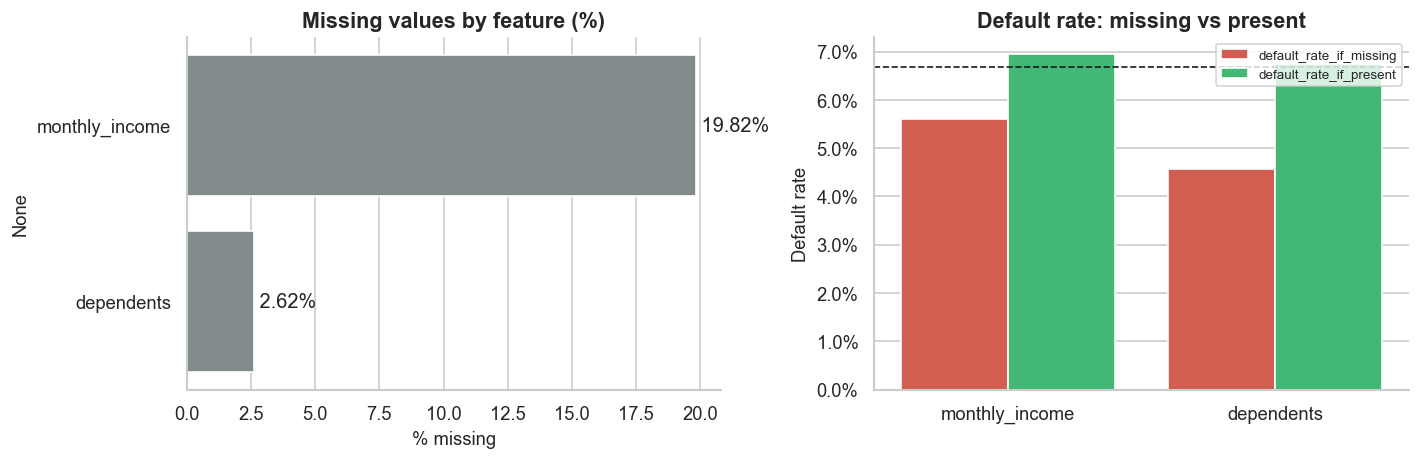

In [29]:
miss = df[FEATURES].isna().mean().mul(100).sort_values(ascending=False)
miss = miss[miss > 0]

rows = []
for c in miss.index:
    g = df.groupby(df[c].isna())[TARGET].agg(["mean", "count"])
    rows.append({"feature": c, "missing_%": miss[c],
                 "default_rate_if_missing": g.loc[True, "mean"],
                 "default_rate_if_present": g.loc[False, "mean"]})
miss_df = pd.DataFrame(rows).set_index("feature")
display(miss_df)

# statistical test: does missingness change the default rate?
for c in miss.index:
    ct = pd.crosstab(df[c].isna(), df[TARGET])
    chi2, p, _, _ = stats.chi2_contingency(ct)
    print(f"{c:15s} chi² = {chi2:8.2f}  p-value = {p:.2e}")

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.barplot(x=miss.values, y=miss.index, color=PALETTE["neutral"], ax=ax[0])
for i, v in enumerate(miss.values): ax[0].text(v, i, f" {v:.2f}%", va="center")
ax[0].set_title("Missing values by feature (%)"); ax[0].set_xlabel("% missing")

plot_df = miss_df[["default_rate_if_missing", "default_rate_if_present"]].reset_index().melt(id_vars="feature")
sns.barplot(data=plot_df, x="feature", y="value", hue="variable",
            palette=[PALETTE["bad"], PALETTE["good"]], ax=ax[1])
ax[1].axhline(BASE_RATE, ls="--", c="k", lw=1)
ax[1].yaxis.set_major_formatter(mticker.PercentFormatter(1.0))
ax[1].set_title("Default rate: missing vs present"); ax[1].set_ylabel("Default rate"); ax[1].set_xlabel("")
ax[1].legend(title="", fontsize=8)
plt.tight_layout(); plt.show()

📌 **Observation:**

- Left panel: `monthly_income` is missing for **19.82%** of borrowers and `dependents` for **2.62%**; no other column has nulls.
- Right panel: the missing groups default **less** often than the observed groups — **5.61% vs 6.95%** for income and **4.56% vs 6.74%** for dependents — and both gaps are statistically significant (chi-square 67.89, p = 1.7e-16 and 28.75, p = 8.2e-8). Missingness is therefore informative, not random, and points in the opposite direction from what a "missing = risky" assumption would predict.
- The size of the missing-income group (about 1 in 5 customers) rules out dropping rows.

💡 **Pipeline decision:**

- **Do not drop rows.** Add `income_missing` and `dependents_missing` indicators so the model can use the signal inside the missingness itself.
- Impute inside the sklearn `Pipeline` so statistics are fitted on the training fold only: **median** for `monthly_income` (training median $5,400) and **0 / mode** for `dependents`.
- Persist the imputation values as pipeline artefacts so the FastAPI service reproduces training behaviour exactly.

---
## Step 5 — Duplicate Detection and Stratified Hold-out
---
**Why:** Exact duplicate rows can cause data leakage — the same borrower record appearing in both the training and the validation set inflates cross-validation scores. De-duplication therefore has to happen **before** any split. Right after it we carve out the stratified hold-out, so that every later statistic is learned from the training data only.  

**Business insight:** The Kaggle file has no applicant ID, so identical rows cannot be proven to be different people. In a real lending system, duplicates usually come from re-submitted applications or extraction errors — both of which would be de-duplicated on the application ID upstream.

In [30]:
dupes = df.duplicated().sum()
print(f"Duplicate rows found: {dupes:,}")

if dupes > 0:
    dupe_mask = df.duplicated(keep=False)
    print("\nClass breakdown of duplicate rows:")
    print(df[dupe_mask][TARGET].value_counts().to_string())
    df = df.drop_duplicates().reset_index(drop=True)
    print(f"\n✅ Duplicates removed. New shape: {df.shape}")
else:
    print("✅ No duplicates found — dataset is clean")

# ── Stratified hold-out: ALL further EDA (Step 7 onward) uses `train` only ──
train, holdout = train_test_split(df, test_size=0.20, stratify=df[TARGET], random_state=RANDOM_STATE)
BASE_RATE = train[TARGET].mean()
print(f"\ntrain   : {len(train):>8,} rows | default rate {BASE_RATE:.3%}")
print(f"hold-out: {len(holdout):>8,} rows | default rate {holdout[TARGET].mean():.3%}")

Duplicate rows found: 609

Class breakdown of duplicate rows:
default
0    928
1     32

✅ Duplicates removed. New shape: (149391, 11)

train   :  119,512 rows | default rate 6.700%
hold-out:   29,879 rows | default rate 6.700%


📌 **Observation:**

- **609 exact duplicate rows (0.41%)** are found; the duplicated groups contain 928 good and 32 bad rows (both copies counted). After `drop_duplicates()` the file has **149,391 rows**, and the default count moves from 10,026 to 10,009, so the default rate stays at **6.700%**.
- The stratified split gives **119,512 training rows (6.700% default)** and **29,879 hold-out rows (6.700% default)** — the two partitions are directly comparable.

💡 **Pipeline decision:** `drop_duplicates()` runs inside `validate_input_data()` **before** `train_test_split`, so no identical row can appear in both partitions. The hold-out is touched only once, for the final model report; hyper-parameter tuning uses `StratifiedKFold` inside the training split.

---
## Step 6 — Statistical Summary Heatmap
---
**Why:** Descriptive statistics for features with very different scales (age in years, income in thousands, ratios near 1) are hard to compare in a table. A column-normalised heatmap instantly highlights which features have the widest spread, the most extreme maxima or the largest coefficient of variation.  

**Business insight:** Features whose maximum or spread is wildly out of proportion to their typical value usually indicate data-capture problems (placeholder codes, unit errors) rather than genuine customer behaviour. Finding them now prevents distorted model coefficients later.

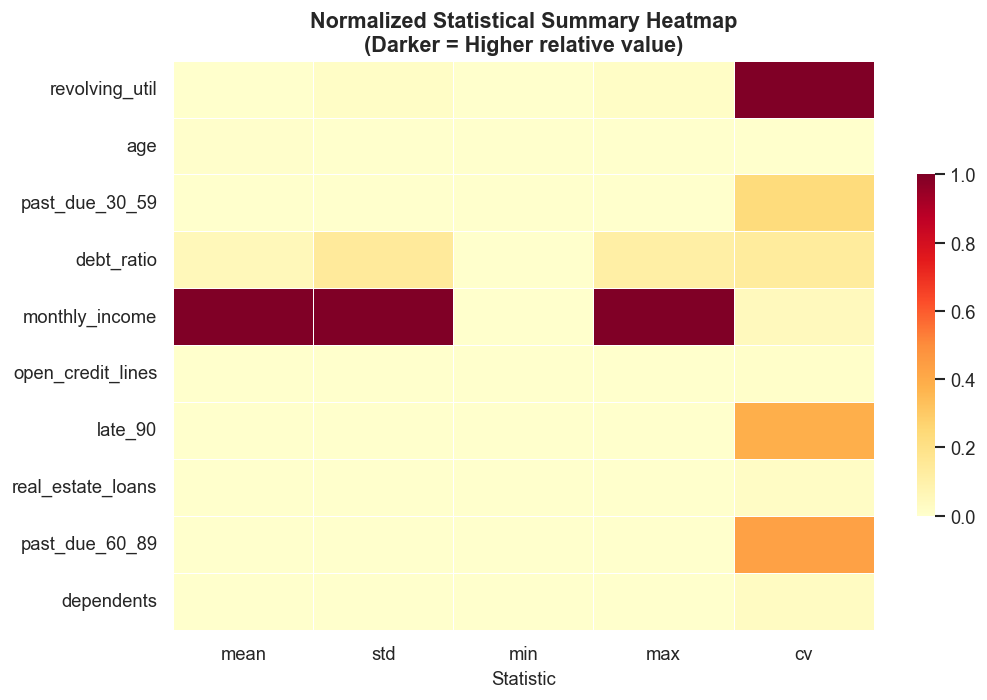

Top 5 features by Coefficient of Variation (most variable):
revolving_util    41.22
past_due_60_89    17.93
late_90           16.07
past_due_30_59     9.78
debt_ratio         5.76


In [31]:
desc = df[FEATURES].describe().T
desc["cv"] = (desc["std"] / desc["mean"].replace(0, 1)).abs()

# Normalise per column for the heatmap
norm = MinMaxScaler()
desc_norm = pd.DataFrame(
    norm.fit_transform(desc[["mean", "std", "min", "max", "cv"]]),
    index=desc.index,
    columns=["mean", "std", "min", "max", "cv"]
)

fig, ax = plt.subplots(figsize=(9, 6))
sns.heatmap(desc_norm, annot=False, cmap="YlOrRd", linewidths=0.3, ax=ax, cbar_kws={"shrink": 0.6})
ax.set_title("Normalized Statistical Summary Heatmap\n(Darker = Higher relative value)")
ax.set_xlabel("Statistic")
plt.tight_layout()
plt.show()

print("Top 5 features by Coefficient of Variation (most variable):")
print(desc["cv"].sort_values(ascending=False).head(5).round(2).to_string())

📌 **Observation:**

- In the normalised heatmap `monthly_income` is the darkest cell in the `mean`, `std` and `max` columns (a $3.0M maximum), with `debt_ratio` a clearly lighter second; every other feature is pale in those columns. The `min` column is uniformly pale because every minimum is 0.
- The `cv` column singles out **`revolving_util` (CV 41.2)** as the darkest cell, followed by **`past_due_60_89` (17.9)** and **`late_90` (16.1)** in orange, then `past_due_30_59` (9.8) and `debt_ratio` (5.8). A CV of 40 means the standard deviation is 40 times the mean — for counters that are zero for most customers this can only come from a few extreme rows.
- `age`, `open_credit_lines`, `real_estate_loans` and `dependents` are pale throughout — compact, well-behaved features.

💡 **Pipeline decision:** The extreme rows behind the high CV values are investigated individually in Steps 9–13 rather than clipped blindly. `revolving_util` and `debt_ratio` are winsorised at training-set percentiles, the delinquency counters get a dedicated sentinel-code rule, and `monthly_income` is log-transformed and capped.

---
## Step 7 — Class Imbalance Analysis
---
**Why:** This is the most important insight for the whole model design. A naive model predicting "Good" for every borrower achieves ~93% accuracy while catching **zero** defaulters — completely useless for the business. The class balance dictates the evaluation metric, the sampling strategy and the validation scheme.  

**Business insight:** Defaults are rare but expensive — portfolio loss is driven by the small bad class. The imbalance ratio of roughly 14 : 1 means traditional accuracy is deceptive, which drives the choice of **ROC-AUC, PR-AUC and the KS statistic** as primary metrics and motivates cost-based threshold selection.

Good borrowers              :  139,382  (93.300%)
Defaulted borrowers         :   10,009  (6.700%)
Imbalance ratio             : 13.9:1

Dummy model accuracy (predict all Good) : 93.30%  ← misleading!
Dummy model recall on defaulters        :   0.00%  ← zero defaulters caught


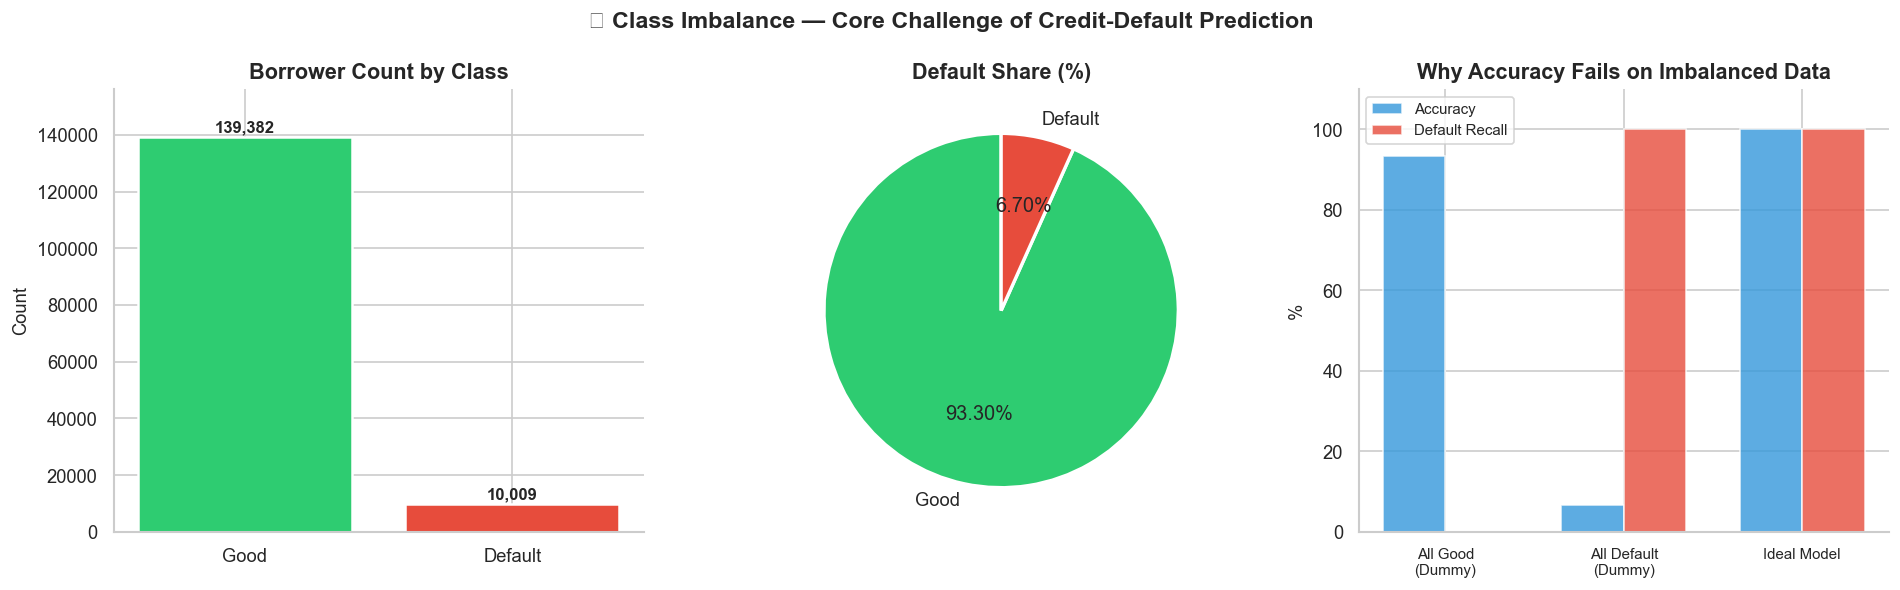

In [32]:
counts       = df[TARGET].value_counts().sort_index()
default_rate = df[TARGET].mean() * 100

good_n, bad_n = counts[0], counts[1]
ratio = good_n / bad_n

print(f"{'Good borrowers':<28}: {good_n:>8,}  ({100 - default_rate:.3f}%)")
print(f"{'Defaulted borrowers':<28}: {bad_n:>8,}  ({default_rate:.3f}%)")
print(f"{'Imbalance ratio':<28}: {ratio:.1f}:1")
print()

# Dummy model accuracy
dummy_acc = good_n / (good_n + bad_n) * 100
print(f"Dummy model accuracy (predict all Good) : {dummy_acc:.2f}%  ← misleading!")
print(f"Dummy model recall on defaulters        :   0.00%  ← zero defaulters caught")

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# Bar chart
axes[0].bar(["Good", "Default"], [good_n, bad_n], color=[GOOD_COLOR, BAD_COLOR], edgecolor="white", linewidth=1.5)
axes[0].set_title("Borrower Count by Class")
axes[0].set_ylabel("Count")
for i, v in enumerate([good_n, bad_n]):
    axes[0].text(i, v + 1500, f"{v:,}", ha="center", fontweight="bold", fontsize=10)
axes[0].set_ylim(0, good_n * 1.12)

# Pie chart
axes[1].pie([good_n, bad_n], labels=["Good", "Default"], colors=[GOOD_COLOR, BAD_COLOR],
            autopct="%1.2f%%", startangle=90, wedgeprops={"edgecolor": "white", "linewidth": 2})
axes[1].set_title("Default Share (%)")

# Why accuracy fails
categories = ["All Good\n(Dummy)", "All Default\n(Dummy)", "Ideal Model"]
accuracy   = [dummy_acc, default_rate, 100]
recall_bad = [0, 100, 100]
x, w = np.arange(3), 0.35
axes[2].bar(x - w/2, accuracy,   w, label="Accuracy",        color=ACCENT_COLOR, alpha=0.8)
axes[2].bar(x + w/2, recall_bad, w, label="Default Recall",  color=BAD_COLOR,    alpha=0.8)
axes[2].set_xticks(x); axes[2].set_xticklabels(categories, fontsize=9)
axes[2].set_ylim(0, 110); axes[2].set_ylabel("%")
axes[2].set_title("Why Accuracy Fails on Imbalanced Data")
axes[2].legend(fontsize=9)

plt.suptitle("🚨 Class Imbalance — Core Challenge of Credit-Default Prediction",
             fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

📌 **Observation:**

- **139,382 good borrowers (93.300%) vs 10,009 defaulters (6.700%)** — an imbalance of **13.9 : 1**. The bar chart and pie show the same split.
- The right panel makes the accuracy trap concrete: a dummy "everyone is good" model scores **93.30% accuracy with 0% default recall**, while a dummy "everyone defaults" model catches 100% of defaulters at 6.7% accuracy. Neither is useful, and accuracy hides the difference.
- The imbalance is moderate — the minority class has ~8,000 cases in the training split, far more than in card fraud.

💡 **Pipeline decision:**

- **Never use accuracy.** Primary metrics: **ROC-AUC, PR-AUC, KS and Gini**; the decision threshold is chosen by expected-loss cost, not 0.5.
- All cross-validation uses `StratifiedKFold`; the hold-out is used once.
- Imbalance is handled with `class_weight` / `scale_pos_weight` first (compared with SMOTE in Step 20) and a **calibration stage** (isotonic / Platt) is mandatory, because underwriting consumes probabilities of default, not only rankings.

---
## Step 8 — Univariate distributions & skewness
---
**Why:** Histograms on a `log1p` scale reveal the true shape of heavy-tailed financial variables, which are unreadable on a linear axis. Reporting skewness numerically tells us which variables need a transform for linear/scorecard models.  

**Business insight:** Financial quantities (income, balances, ratios) are multiplicative by nature. Credit-risk scorecards and logistic regression assume roughly well-behaved inputs, so understanding shape is the first step toward a stable, explainable PD model.

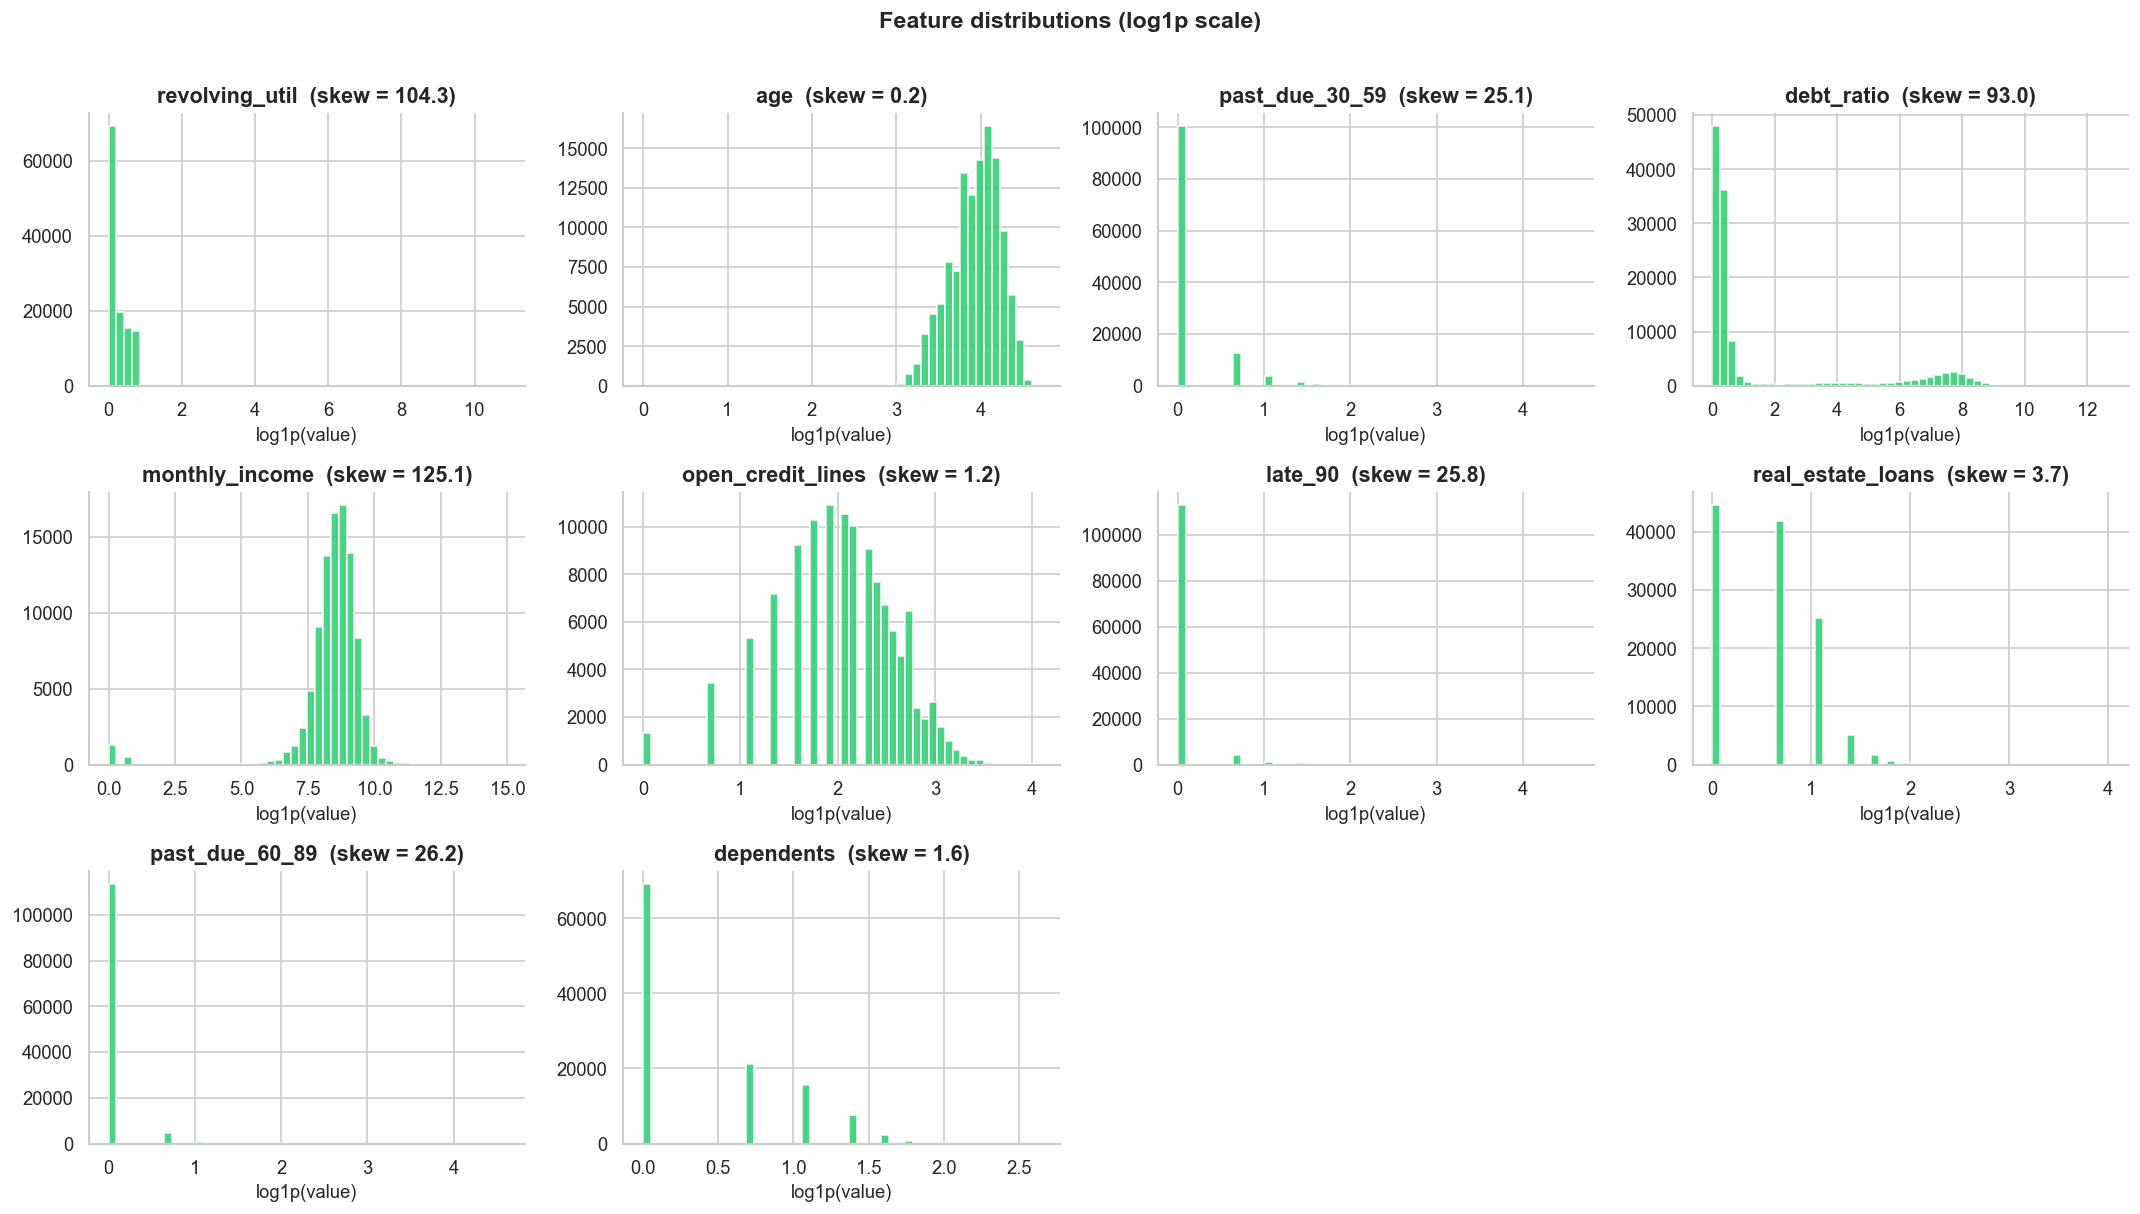

,skewness,needs_transform
monthly_income,125.097794,True
revolving_util,104.279989,True
debt_ratio,93.013539,True
past_due_60_89,26.150348,True
late_90,25.806313,True
past_due_30_59,25.129024,True
real_estate_loans,3.748261,True
dependents,1.562362,True
open_credit_lines,1.235657,True
age,0.188259,False


In [33]:
fig, axes = plt.subplots(3, 4, figsize=(18, 10)); axes = axes.ravel()
for ax, c in zip(axes, FEATURES):
    s = train[c].dropna()
    ax.hist(np.log1p(s.clip(lower=0)), bins=50, color=PALETTE["good"], alpha=0.85)
    ax.set_title(f"{c}  (skew = {s.skew():.1f})"); ax.set_xlabel("log1p(value)")
for ax in axes[len(FEATURES):]: ax.axis("off")
plt.suptitle("Feature distributions (log1p scale)", y=1.01, fontsize=14, fontweight="bold")
plt.tight_layout(); plt.show()

skew_tbl = train[FEATURES].skew().sort_values(ascending=False).to_frame("skewness")
skew_tbl["needs_transform"] = skew_tbl["skewness"].abs() > 1
display(skew_tbl)

📌 **Observation:**

- Skewness ranking: `monthly_income` **125.1**, `revolving_util` **104.3**, `debt_ratio` **93.0**, then the three delinquency counters at **25–26**; `real_estate_loans` 3.7, `dependents` 1.6 and `open_credit_lines` 1.2 are mildly skewed; `age` (0.19) is the only feature that does not need a transform.
- On the log1p grid, `revolving_util` is a single mass below ~1 with an almost invisible tail out to ~11, and the three delinquency counters are one giant spike at 0 (over 100,000 of 119,512 rows) with tiny bars at 1, 2, 3 — they are **zero-inflated counts**.
- `debt_ratio` is **bimodal**: a large mass near 0–1 and a second hump around log1p 6–9 (ratios of roughly 400–8,000). That second hump cannot be genuine ratios; it is the income-missing group examined in Step 13.
- `monthly_income` is bell-shaped around log1p ≈ 8.5–9 (about $5,000–8,000) with a small separate bump at 0 — zero-income records.

💡 **Pipeline decision:**

- Apply **`log1p`** to monthly income and any derived money feature, and **winsorise** `revolving_util` and `debt_ratio` (caps set in Steps 11 and 13).
- Keep delinquency counters as counts for tree models and **bucket them (0 / 1 / 2 / 3+)** for the scorecard branch.
- Transforms live in a **model-specific preprocessing branch** (linear vs tree) rather than one global step — tree models do not need them.

---
## Step 9 — Outliers & sentinel codes in delinquency features
---
**Why:** Percentile tables and value-frequency plots (log y-axis) expose the difference between a *genuine extreme* and a *system code*. Delinquency counters with values of 96 and 98 are not credible counts of late payments in two years — they are classic placeholder codes. Comparing the default rate of those rows to the rest tells us whether the code carries information.  

**Business insight:** If a core-banking or bureau extract writes a special code when the payment history is unknown or unavailable, the correct treatment is a **policy decision**, not an automated clip. Mishandling it would badly distort the most important risk drivers.

Percentile profile (train):


,0.500,0.900,0.990,0.999,1.000
revolving_util,0.153620,0.977802,1.092195,1564.956,50708.0
age,52.000000,72.000000,87.000000,94.000,109.0
past_due_30_59,0.000000,1.000000,4.000000,98.000,98.0
debt_ratio,0.367726,1274.000000,4937.890000,11020.954,329664.0
monthly_income,5400.000000,11666.000000,25000.000000,77265.472,3008750.0
open_credit_lines,8.000000,15.000000,25.000000,35.000,58.0
late_90,0.000000,0.000000,2.000000,98.000,98.0
real_estate_loans,1.000000,2.000000,4.000000,9.000,54.0
past_due_60_89,0.000000,0.000000,2.000000,98.000,98.0
dependents,0.000000,2.000000,4.000000,6.000,13.0



Rows with a 96/98 code in ANY delinquency column: 170 (0.14%) | in ALL three: 170
  past_due_30_59  → values 96:    4   98:  166
  past_due_60_89  → values 96:    4   98:  166
  late_90         → values 96:    4   98:  166


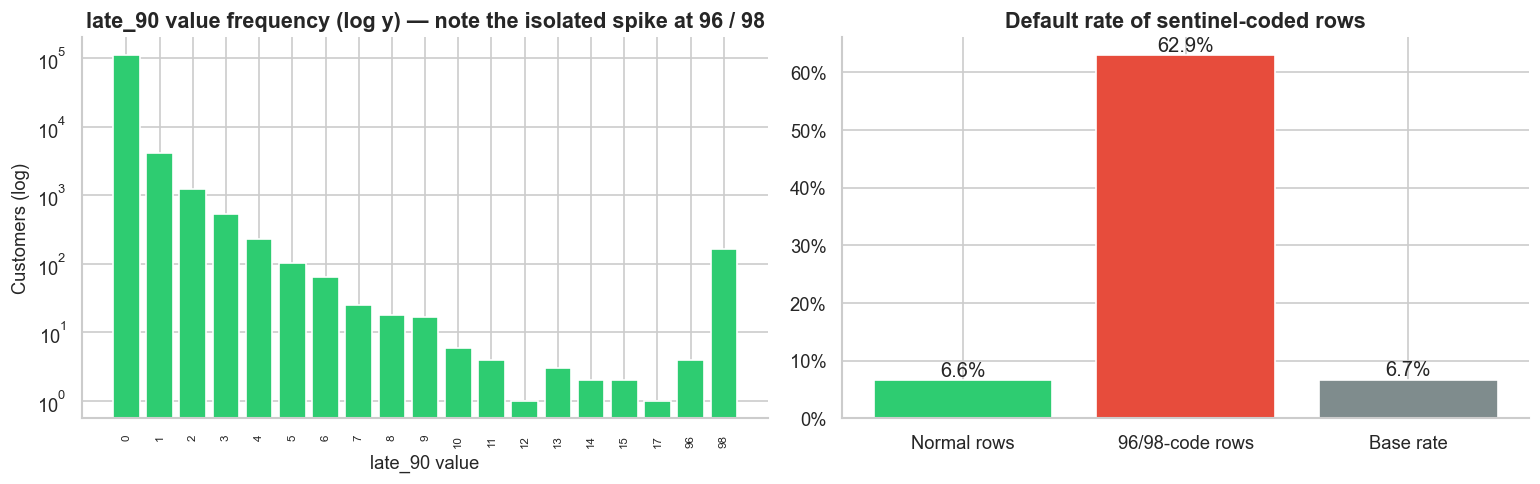

In [34]:
print("Percentile profile (train):")
display(train[FEATURES].quantile([.5, .9, .99, .999, 1.0]).T)

sent_mask = (train[DELINQ] >= 96).any(axis=1)
print(f"\nRows with a 96/98 code in ANY delinquency column: {sent_mask.sum():,} "
      f"({sent_mask.mean():.2%}) | in ALL three: {(train[DELINQ] >= 96).all(axis=1).sum():,}")
for c in DELINQ:
    print(f"  {c:15s} → values 96: {(train[c]==96).sum():4d}   98: {(train[c]==98).sum():4d}")

fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
vc = train["late_90"].value_counts().sort_index()
ax[0].bar(vc.index.astype(str), vc.values, color=PALETTE["good"]); ax[0].set_yscale("log")
ax[0].set_title("late_90 value frequency (log y) — note the isolated spike at 96 / 98")
ax[0].set_xlabel("late_90 value"); ax[0].set_ylabel("Customers (log)")
ax[0].tick_params(axis="x", rotation=90, labelsize=7)

grp = pd.Series({"Normal rows": train.loc[~sent_mask, TARGET].mean(),
                 "96/98-code rows": train.loc[sent_mask, TARGET].mean(),
                 "Base rate": BASE_RATE})
ax[1].bar(grp.index, grp.values, color=[PALETTE["good"], PALETTE["bad"], PALETTE["neutral"]])
for i, v in enumerate(grp.values): ax[1].text(i, v, f"{v:.1%}", ha="center", va="bottom")
ax[1].yaxis.set_major_formatter(mticker.PercentFormatter(1.0)); ax[1].set_title("Default rate of sentinel-coded rows")
plt.tight_layout(); plt.show()

📌 **Observation:**

- Left panel: `late_90` falls smoothly on the log axis from ~110,000 customers at 0 down to a single customer at 12 and 17, then jumps to **166 customers at 98 and 4 at 96**. The genuine counts end at 17; 96 / 98 are system codes.
- **170 rows (0.14%)** carry a 96 or 98 code, and in **all 170 the code appears in all three delinquency columns simultaneously**.
- Right panel: those rows default at **62.9%**, versus **6.6%** for normal rows and 6.7% for the base rate — about **9.4× the normal default rate**. The code is meaningless as a number but highly informative as a flag.
- The percentile table also shows two other issues: the 99.9th percentile of `revolving_util` is 1,565 (the 99th is only 1.09), and the 90th percentile of `debt_ratio` is already **1,274** — more than 10% of customers have a "ratio" above 1,000.

💡 **Pipeline decision:**

- Create **`delinq_sentinel_flag`** where any delinquency column is ≥ 96, then **replace 96 / 98 with NaN** and impute (median = 0) inside the pipeline. The flag keeps the signal; the imputation removes the numeric distortion.
- Never `clip()` these columns blindly — that would turn 98 into a plausible-looking but false count.
- Document "96 / 98 = placeholder code" in the data-quality contract and add a **drift monitor on the flag rate** (currently 0.14%).

---
## Step 10 — Age: distribution by class and default rate by age band
---
**Why:** Overlaid class distributions show whether a variable separates good from bad customers at all, and a banded default-rate chart converts that into an actionable, monotonic relationship that credit policy can interpret.  

**Business insight:** Age is a proxy for credit maturity and financial stability. It is also a **regulated / sensitive attribute** in many jurisdictions, so its use and its effect size must be understood and defensible in fairness reviews.

Rows with age < 18: 1 | min age: 0 | max age: 109


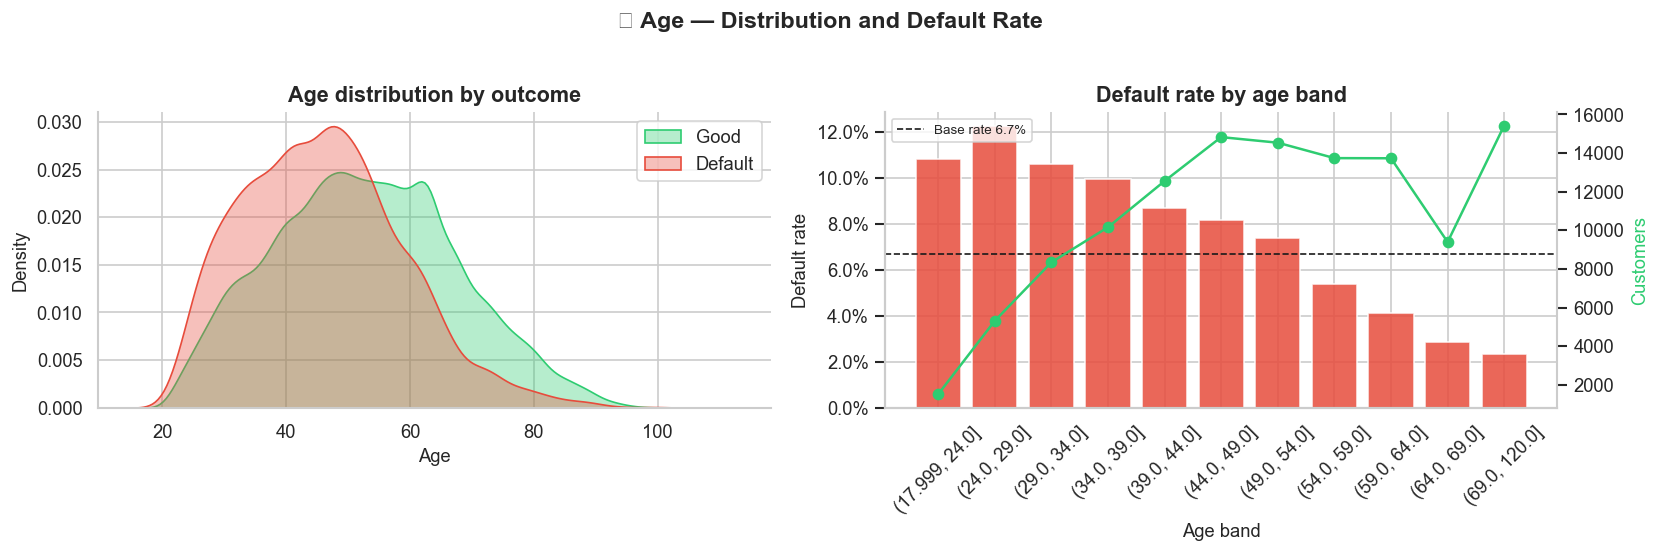

,default_rate,customers,lift_vs_base
age,,,
"(17.999, 24.0]",0.108251,1515,1.615745
"(24.0, 29.0]",0.122341,5313,1.826061
"(29.0, 34.0]",0.105944,8344,1.581320
"(34.0, 39.0]",0.099331,10158,1.482602
"(39.0, 44.0]",0.086780,12549,1.295270
"(44.0, 49.0]",0.081635,14822,1.218485
"(49.0, 54.0]",0.073694,14533,1.099957
"(54.0, 59.0]",0.053877,13735,0.804164
"(59.0, 64.0]",0.040941,13727,0.611086


In [35]:
print(f"Rows with age < 18: {(train['age'] < 18).sum()} | min age: {train['age'].min()} | max age: {train['age'].max()}")
a = train[train["age"] >= 18]

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
for lbl, col, name in [(0, PALETTE["good"], "Good"), (1, PALETTE["bad"], "Default")]:
    sns.kdeplot(a.loc[a[TARGET] == lbl, "age"], fill=True, alpha=0.35, color=col, label=name, ax=ax[0])
ax[0].set_title("Age distribution by outcome"); ax[0].set_xlabel("Age"); ax[0].legend()

age_bins = [18, 24, 29, 34, 39, 44, 49, 54, 59, 64, 69, 120]
t = rate_table(a, "age", bins=age_bins)
plot_rate(t, ax[1], "Default rate by age band", "Age band")
plt.suptitle("🎂 Age — Distribution and Default Rate", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout(); plt.show()
display(t)

📌 **Observation:**

- Left panel: the defaulter density peaks around age 47–48 with a heavy shoulder from 25 to 45; the good-borrower density has a flatter peak and a clearly heavier right tail above 55 (bump near 60–62). Defaulters sit to the left of good customers below ~50, and the order reverses above ~55.
- Right panel: default rate **peaks at 12.2% for ages 25–29** (1.8× the base rate) and is 10.8% for 18–24 (only 1,515 customers). From age 30 it falls steadily: 9.9% (35–39), 8.7% (40–44), 7.4% (50–54), **5.4% (55–59), 4.1% (60–64), 2.8% (65–69) and 2.3% for 70+** (0.35× base) — a **5× spread** between the riskiest and safest band.
- The customer-volume line shows the thinnest cells are the youngest (1,515 customers aged 18–24); the 70+ band is the largest (15,422).
- Exactly **one record has age 0** (minimum 0, maximum 109).

💡 **Pipeline decision:**

- Rule: **`age < 18` → NaN, then impute (training median 52)**; the validation gate logs the count.
- Keep `age` continuous for the GBM champion, and use the age bands above for the WoE scorecard (monotonic from age 30 upward).
- Age is a **sensitive attribute**: register it in the fairness review and compute approval-rate / error-rate parity by age band before any model is promoted (done on the unified policy in `03_unified_risk_analysis`).

---
## Step 11 — Revolving utilisation: tail behaviour & risk gradient
---
**Why:** Utilisation is a *ratio* that is supposed to live between 0 and ~1. A distribution clipped at 2 plus a banded risk curve lets us separate the **legitimate over-limit region (1–2)** from **corrupt values (≫ 10)** and quantify the risk gradient inside the valid range.  

**Business insight:** Utilisation is one of the strongest signals in unsecured lending: customers who max out their credit lines are liquidity-stressed. Underwriters already use utilisation thresholds (e.g. >80 %) in policy rules, so the model should confirm and sharpen them.

util > 1  :  2,654 rows (2.22%)
util > 2  :    290 rows (0.24%)
util > 10 :    190 rows (0.16%)
p99 = 1.092 | p99.9 = 1564.96 | max = 50,708


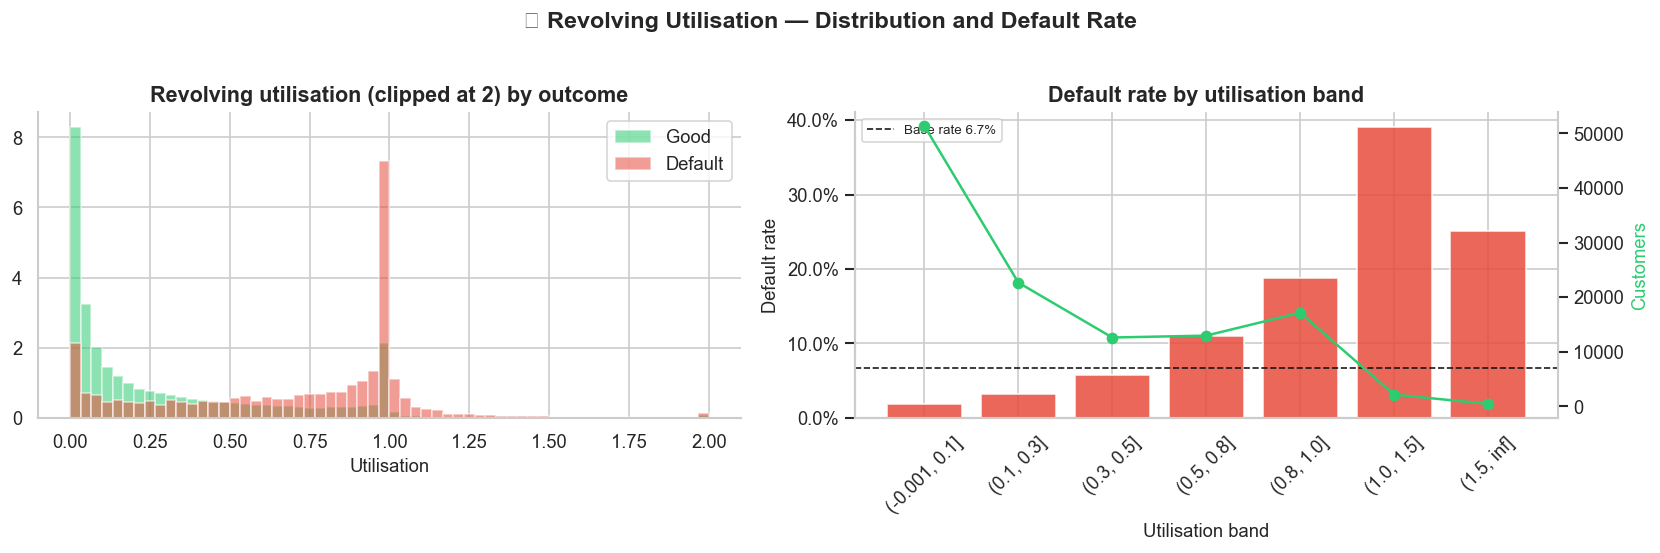

,default_rate,customers,lift_vs_base
revolving_util,,,
"(-0.001, 0.1]",0.018083,51374,0.269907
"(0.1, 0.3]",0.031463,22693,0.469622
"(0.3, 0.5]",0.057943,12633,0.864861
"(0.5, 0.8]",0.110118,12977,1.643613
"(0.8, 1.0]",0.188057,17181,2.806921
"(1.0, 1.5]",0.391364,2177,5.841479
"(1.5, inf]",0.251572,477,3.754953


In [36]:
u = train["revolving_util"]
print(f"util > 1  : {(u > 1).sum():6,} rows ({(u > 1).mean():.2%})")
print(f"util > 2  : {(u > 2).sum():6,} rows ({(u > 2).mean():.2%})")
print(f"util > 10 : {(u > 10).sum():6,} rows ({(u > 10).mean():.2%})")
print(f"p99 = {u.quantile(.99):.3f} | p99.9 = {u.quantile(.999):.2f} | max = {u.max():,.0f}")

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
for lbl, col, name in [(0, PALETTE["good"], "Good"), (1, PALETTE["bad"], "Default")]:
    ax[0].hist(u[(train[TARGET] == lbl)].clip(upper=2), bins=60, alpha=0.55, color=col, label=name, density=True)
ax[0].set_title("Revolving utilisation (clipped at 2) by outcome"); ax[0].set_xlabel("Utilisation"); ax[0].legend()

util_bins = [0, .1, .3, .5, .8, 1.0, 1.5, np.inf]
t = rate_table(train, "revolving_util", bins=util_bins)
plot_rate(t, ax[1], "Default rate by utilisation band", "Utilisation band")
plt.suptitle("💳 Revolving Utilisation — Distribution and Default Rate", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout(); plt.show()
display(t)

📌 **Observation:**

- **2,654 rows (2.22%)** have utilisation above 1, 290 above 2 and 190 above 10; the 99th percentile is 1.09, the 99.9th is 1,565 and the maximum is 50,708 — a data-capture error, not a ratio.
- Left panel: good customers pile up at 0 (density ≈ 8), while **defaulters form a sharp spike at exactly 1.0 (density ≈ 7)** — maxed-out credit lines — plus a small bump at the clip value 2.
- Right panel: the risk gradient is steep and monotonic up to 1.0 — **1.8%** (≤ 0.1), 3.1%, 5.8%, **11.0%**, **18.8%** (0.8–1.0) — peaking at **39.1% for utilisation 1.0–1.5** (5.8× the base rate). Above 1.5 the rate **drops back to 25.2%** (only 477 customers): the extreme values include corrupt records that dilute the risk.

💡 **Pipeline decision:**

- Add **`over_limit_flag = revolving_util > 1`** (a genuine business state with a 36.6% default rate, see Step 18) and **winsorise `revolving_util` at the training 99th percentile (1.092, stored in `CAPS`)** to neutralise the corrupt extremes.
- Keep utilisation as a **top-tier feature** with a monotonic constraint (+1) in the GBM.
- Candidate interaction for the model stage: `revolving_util × total_delinq` (liquidity stress combined with payment history).

---
## Step 12 — Delinquency history vs default (sentinel-cleaned)
---
**Why:** Default rate by delinquency count, computed *after* removing the 96/98 codes, shows the true dose–response relationship between past payment behaviour and future default. Three side-by-side panels let us compare severity (30–59 vs 60–89 vs 90+ days).  

**Business insight:** Past delinquency is the most direct behavioural evidence of repayment willingness. How sharply risk escalates with each additional late payment determines policy cut-offs ("decline if ≥ 2 serious delinquencies") and pricing tiers.

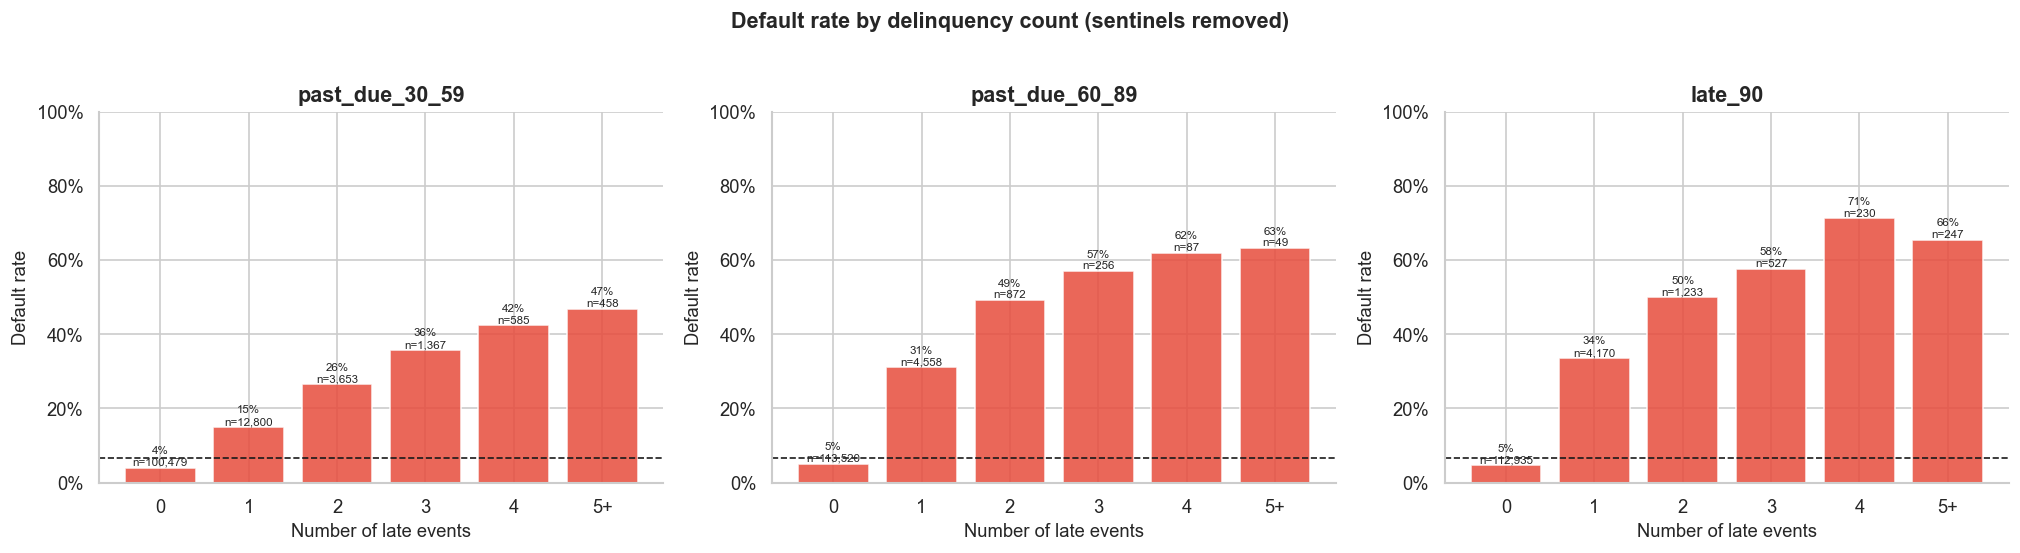

In [37]:
m = mask_sentinels(train)
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
tables = {}
for ax, c in zip(axes, DELINQ):
    t = rate_by_value(m.dropna(subset=[c]), c, cap=5)
    tables[c] = t
    ax.bar(t.index, t["default_rate"], color=PALETTE["bad"], alpha=0.85)
    ax.axhline(BASE_RATE, ls="--", c="k", lw=1)
    for i, (r, n) in enumerate(zip(t["default_rate"], t["customers"])):
        ax.text(i, r, f"{r:.0%}\nn={n:,}", ha="center", va="bottom", fontsize=7)
    ax.yaxis.set_major_formatter(mticker.PercentFormatter(1.0)); ax.set_ylim(0, 1)
    ax.set_title(c); ax.set_xlabel("Number of late events"); ax.set_ylabel("Default rate")
plt.suptitle("Default rate by delinquency count (sentinels removed)", y=1.02, fontsize=13, fontweight="bold")
plt.tight_layout(); plt.show()

📌 **Observation:**

- Risk rises with every extra late event in all three panels. **30–59 days:** 4% (n = 100,479) → 15% → 26% → 36% → 42% → 47% (5+, n = 458). **60–89 days:** 5% (n = 113,526) → **31%** → 49% → 57% → 62% → 63% (5+, n = 49). **90+ days:** 5% (n = 112,935) → **34%** → 50% → 58% → **71% (4 events, n = 230)** → 66% (5+, n = 247).
- A **single** 60–89-day or 90+-day event already lifts default risk to roughly **5× the base rate**, while a single 30–59-day event lifts it to 2.2×. Customers with 2+ serious (60+ day) events are at 50% and above.
- The relationship is monotonic up to 3 events; the last buckets are small (n = 49–247), so the dip from 71% to 66% in the 90+ panel is noise rather than a real reversal.
- Volume collapses quickly: more than 100,000 customers have zero events in each column.

💡 **Pipeline decision:**

- Engineer severity-aware aggregates: **`total_delinq`**, **`severity_score = 1·(30-59) + 2·(60-89) + 3·(90+)`** and **`any_delinq`**.
- Cap counts at **3+** for the scorecard branch (the 4+ / 5+ buckets are too small to be stable); keep raw counts for GBM.
- Apply **monotonic constraints (+1)** to all delinquency features in the champion model — more late payments can never lower risk.

---
## Step 13 — Debt ratio: the income-missing anomaly
---
**Why:** Comparing `debt_ratio` between customers with and without income (log-scale boxplot) is a **diagnostic for field semantics**. A ratio should have the same scale for everyone; if it does not, the column is mixing two different definitions.  

**Business insight:** Debt-to-income (DTI) is a cornerstone affordability metric in underwriting. A DTI that is unreliable for 20 % of the portfolio would produce wrong affordability decisions, so the root cause needs to be understood and fixed in the data rather than hidden by a model.

,count,mean,std,min,50%,90%,99%,max
income_missing,,,,,,,,
False,96083.0,26.654003,448.767478,0.0,0.295408,0.759657,633.54,61106.5
True,23429.0,1714.812412,4676.222952,0.0,1197.000000,3803.000000,8024.60,329664.0


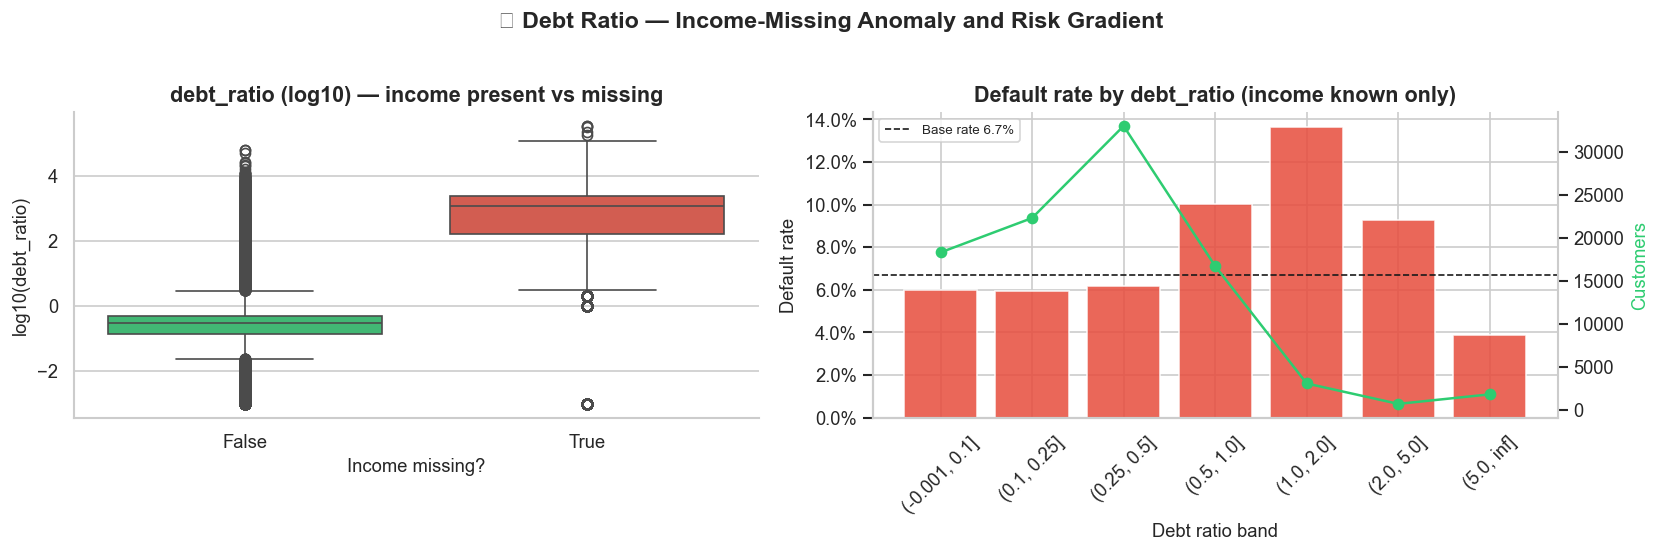

,default_rate,customers,lift_vs_base
debt_ratio,,,
"(-0.001, 0.1]",0.059986,18321,0.895345
"(0.1, 0.25]",0.059693,22314,0.890981
"(0.25, 0.5]",0.061850,32999,0.923175
"(0.5, 1.0]",0.100233,16741,1.496071
"(1.0, 2.0]",0.136568,3112,2.038408
"(2.0, 5.0]",0.092617,745,1.382402
"(5.0, inf]",0.038898,1851,0.580588


Rows with debt_ratio > 1 → income known: 5.94% | income missing: 95.47%


In [38]:
tmp = train.assign(income_missing=train["monthly_income"].isna())
tmp["log10_debt_ratio"] = np.log10(tmp["debt_ratio"].clip(lower=1e-3))
display(tmp.groupby("income_missing")["debt_ratio"].describe(percentiles=[.5, .9, .99]))

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
sns.boxplot(data=tmp, x="income_missing", y="log10_debt_ratio", palette=[PALETTE["good"], PALETTE["bad"]], ax=ax[0])
ax[0].set_title("debt_ratio (log10) — income present vs missing"); ax[0].set_xlabel("Income missing?"); ax[0].set_ylabel("log10(debt_ratio)")

known = train[train["monthly_income"].notna()]
t = rate_table(known, "debt_ratio", bins=[0, .1, .25, .5, 1, 2, 5, np.inf])
plot_rate(t, ax[1], "Default rate by debt_ratio (income known only)", "Debt ratio band")
plt.suptitle("🧮 Debt Ratio — Income-Missing Anomaly and Risk Gradient", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout(); plt.show()
display(t)
print(f"Rows with debt_ratio > 1 → income known: {(known['debt_ratio'] > 1).mean():.2%} | income missing: {(tmp.loc[tmp.income_missing, 'debt_ratio'] > 1).mean():.2%}")

📌 **Observation:**

- Left panel: with income present, `debt_ratio` behaves like a ratio — median **0.30**, 90th percentile **0.76** (although a long outlier cloud reaches 10^4.7). With income missing, the whole box sits three orders of magnitude higher: median **1,197**, 90th percentile **3,803**, maximum 329,664.
- **95.5% of income-missing rows have `debt_ratio` > 1, against 5.9% of income-known rows.** In the missing group the field holds an absolute debt amount, not a ratio.
- Right panel (income known only): default rate is flat at **6.0–6.2%** up to a ratio of 0.5, then rises to **10.0%** (0.5–1) and **13.7% (1–2)** — a gentle gradient compared with utilisation. It then **falls to 9.3% (2–5) and 3.9% (> 5)**, below the base rate, on only 745 and 1,851 customers. A debt ratio above 5 with a *known* income is almost certainly another broken case (a zero or placeholder income, see Step 14), not low risk.

💡 **Pipeline decision:**

- Rule: **for `income_missing == 1`, set `debt_ratio = NaN`** and impute with the income-known median; the Step 4 flag preserves the information.
- ⚠️ **Review item:** extend the repair rule to `monthly_income == 0` and test whether the `debt_ratio > 5` rows with known income coincide with zero / placeholder incomes. The current winsorisation cap (the training 99th percentile of income-known rows) is **633.5** — far above any meaningful ratio, so it truncates only the extreme tail and does not repair the semantics; a cap near 5, or treating values above it as invalid, is the safer choice.
- Create **`monthly_debt_payment = debt_ratio × monthly_income`** only where both are valid (validated in Step 18) and raise a **data-quality ticket**: the DTI field mixes two meanings when income is absent.

---
## Step 14 — Monthly income: decile risk profile
---
**Why:** Income is highly skewed, so fixed-width bins would put almost everyone into one bucket. **Quantile (decile) binning** gives equally sized groups and makes the risk-vs-income curve comparable and stable; a log-scale density overlay shows the separation between classes.  

**Business insight:** Income is the borrower's capacity to repay. Underwriting needs to know whether the risk gradient is steep (income is a strong cut-off driver) or flat (income adds little beyond behaviour variables) and how to treat the 20 % of applicants with no income on file.

income = 0: 1,284 rows | p99.5 = 35,000 | max = 3,008,750


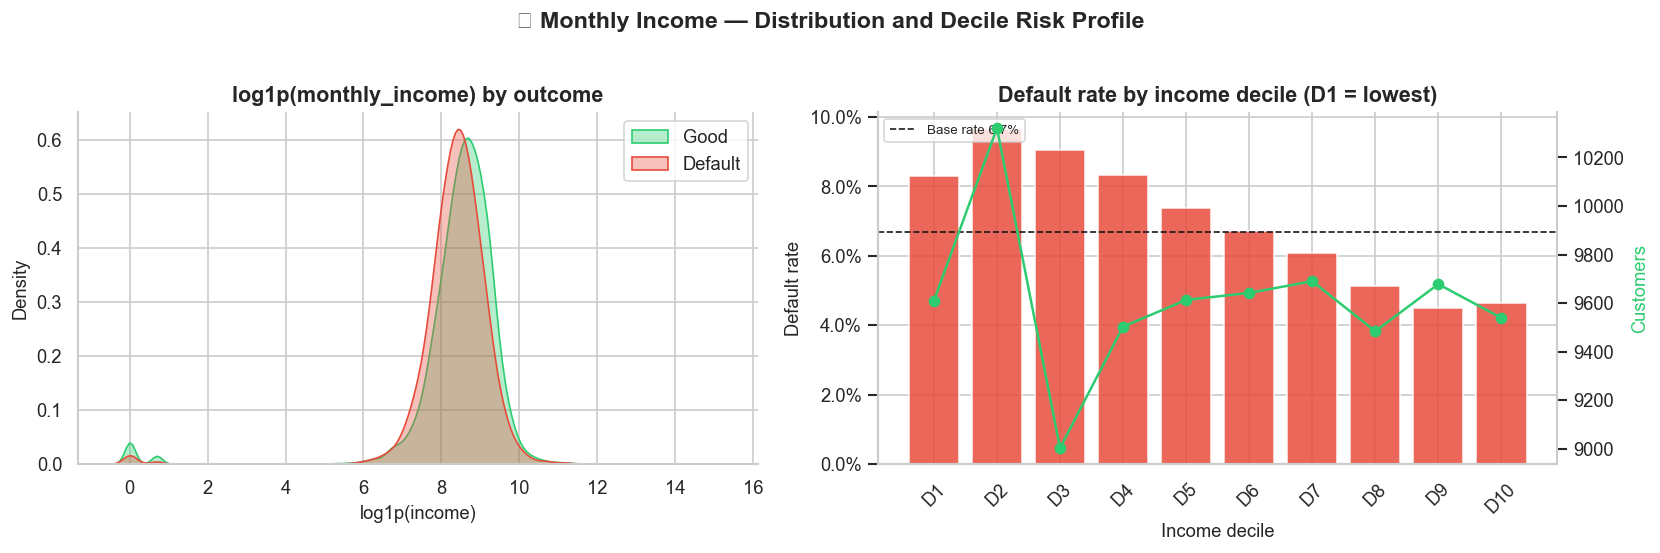

Income-missing group default rate: 5.51%


,default_rate,customers,lift_vs_base
D1,0.083039,9610,1.239428
D2,0.096599,10321,1.441833
D3,0.090636,9003,1.352834
D4,0.083342,9503,1.243959
D5,0.073858,9613,1.102405
D6,0.067206,9642,1.003112
D7,0.060784,9690,0.907263
D8,0.051350,9484,0.766442
D9,0.045051,9678,0.672423
D10,0.046441,9539,0.693174


In [39]:
inc = train.dropna(subset=["monthly_income"])
print(f"income = 0: {(inc['monthly_income'] == 0).sum():,} rows | p99.5 = {inc['monthly_income'].quantile(.995):,.0f} | max = {inc['monthly_income'].max():,.0f}")

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
for lbl, col, name in [(0, PALETTE["good"], "Good"), (1, PALETTE["bad"], "Default")]:
    sns.kdeplot(np.log1p(inc.loc[inc[TARGET] == lbl, "monthly_income"]), fill=True, alpha=0.35, color=col, label=name, ax=ax[0])
ax[0].set_title("log1p(monthly_income) by outcome"); ax[0].set_xlabel("log1p(income)"); ax[0].legend()

t = rate_table(inc, "monthly_income", q=10)
t.index = [f"D{i+1}" for i in range(len(t))]
plot_rate(t, ax[1], "Default rate by income decile (D1 = lowest)", "Income decile")
plt.suptitle("💰 Monthly Income — Distribution and Decile Risk Profile", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout(); plt.show()
print("Income-missing group default rate:", f"{train.loc[train['monthly_income'].isna(), TARGET].mean():.2%}")
display(t)

📌 **Observation:**

- The log1p KDE shows two nearly identical bell curves around log1p ≈ 8.5 (about $5,000), with the defaulter curve slightly shifted left, plus tiny bumps at log1p = 0 and ≈ 0.7 — records with income **0 and 1**. There are **1,284 zero-income rows**; the 99.5th percentile is $35,000 (the winsorisation cap) and the maximum is $3,008,750.
- Decile chart: default rate **peaks at D2 (9.66%)**, is 8.30% in D1, then declines almost steadily to **4.51% in D9 and 4.64% in D10** — a spread of about **2.1×** from D2 to D9. D1 is *below* D2 because it contains the zero- and one-dollar placeholder incomes.
- Customers with **no income on file default at 5.51%**, below the 6.7% base rate (Step 4).
- Income separates the classes far less than utilisation (1.8%→39%) or delinquency history.

💡 **Pipeline decision:**

- Use **`log1p(monthly_income)`** for linear / scorecard models and winsorise at the training 99.5th percentile (**$35,000**).
- Impute missing income with the training median ($5,400) — refined to the median within age bands — and keep `income_missing`; treat income values of 0 and 1 as suspected placeholders (see the Step 13 review item).
- Income is a **supporting feature**: its IV is only 0.073 (Step 17), and it gains value mainly through affordability features such as `income_per_dependent` (IV 0.096, Step 18).

---
## Step 15 — Credit lines, real-estate loans & dependents
---
**Why:** Small discrete count features are best examined with a **default-rate-by-value** plot (top-coded at a sensible cap) rather than histograms. This reveals non-linear or non-monotonic effects that correlation coefficients hide.  

**Business insight:** Portfolio composition matters: too few lines can mean a thin file, too many can mean over-extension, while a mortgage typically signals stability and collateralised commitment. Dependents proxy for household financial burden.

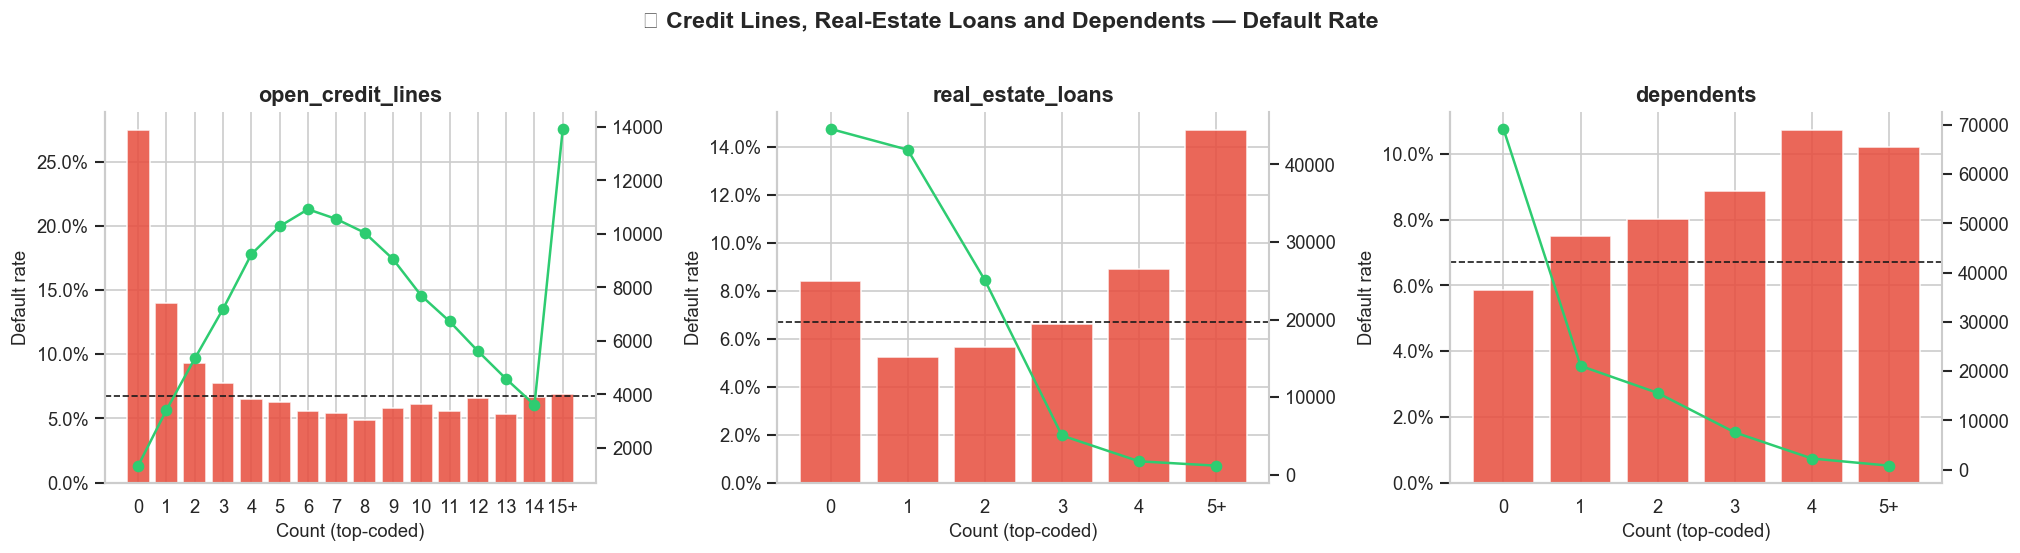

In [40]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for ax, (c, cap) in zip(axes, [("open_credit_lines", 15), ("real_estate_loans", 5), ("dependents", 5)]):
    t = rate_by_value(train.dropna(subset=[c]), c, cap)
    ax.bar(t.index, t["default_rate"], color=PALETTE["bad"], alpha=0.85)
    ax.axhline(BASE_RATE, ls="--", c="k", lw=1)
    ax.yaxis.set_major_formatter(mticker.PercentFormatter(1.0))
    ax2 = ax.twinx(); ax2.plot(t.index, t["customers"], color=PALETTE["good"], marker="o"); ax2.grid(False)
    ax2.spines["right"].set_visible(True)
    ax.set_title(c); ax.set_xlabel("Count (top-coded)"); ax.set_ylabel("Default rate")
plt.suptitle("🏠 Credit Lines, Real-Estate Loans and Dependents — Default Rate", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout(); plt.show()

📌 **Observation:**

- **`open_credit_lines`:** the pattern is a sharp drop-and-plateau, not a U-shape. Customers with **0 open lines default at ~27.5%** (about 1,300 customers), **1 line ≈ 14%**, 2 lines ≈ 9%, 3 lines ≈ 8%, and from 4 lines upward the rate is flat at roughly **5.3–6.8%**. Volume peaks at 6–7 lines.
- **`real_estate_loans`:** U-shaped — **8.4% with none**, the minimum of **5.2% with one loan** (5.6% with two), then rising to 6.6%, 8.9% and **14.7% for 5+** (very few customers).
- **`dependents`:** a gentle monotonic climb from **5.8% (none)** through 7.5%, 8.0% and 8.8% to **10.7% (4)**, 10.2% for 5+ — about 1.8× between the two ends.
- All three effects are far weaker than utilisation or delinquency; they matter mostly at the low-count end (no credit line, no dependents).

💡 **Pipeline decision:**

- Do **not** impose monotonic constraints on `open_credit_lines` and `real_estate_loans` (non-monotonic); use WoE buckets such as 0 / 1 / 2–3 / 4–14 / 15+ and 0 / 1–2 / 3–4 / 5+.
- Top-code `open_credit_lines` at 15, `real_estate_loans` at 5 and `dependents` at 5.
- Add a **`no_credit_line_flag`** (`open_credit_lines == 0`) for the scorecard — it isolates a 27% default segment that WoE bucketing would otherwise blur. Treat all three features as secondary and confirm their value with SHAP at the model stage.

---
## Step 16 — Correlation structure: raw vs sentinel-cleaned
---
**Why:** A correlation heatmap reveals linear redundancy and relationships with the target. Showing it **before and after** removing sentinel codes tests whether apparent redundancy is genuine or an artefact of data quality. Spearman (rank) correlation is used for the full matrix because it is robust to outliers and monotonic non-linearity.  

**Business insight:** Highly correlated inputs make regression coefficients unstable and break explainability (adverse-action reason codes). Knowing which variables overlap tells us which ones can be merged, dropped or regularised.

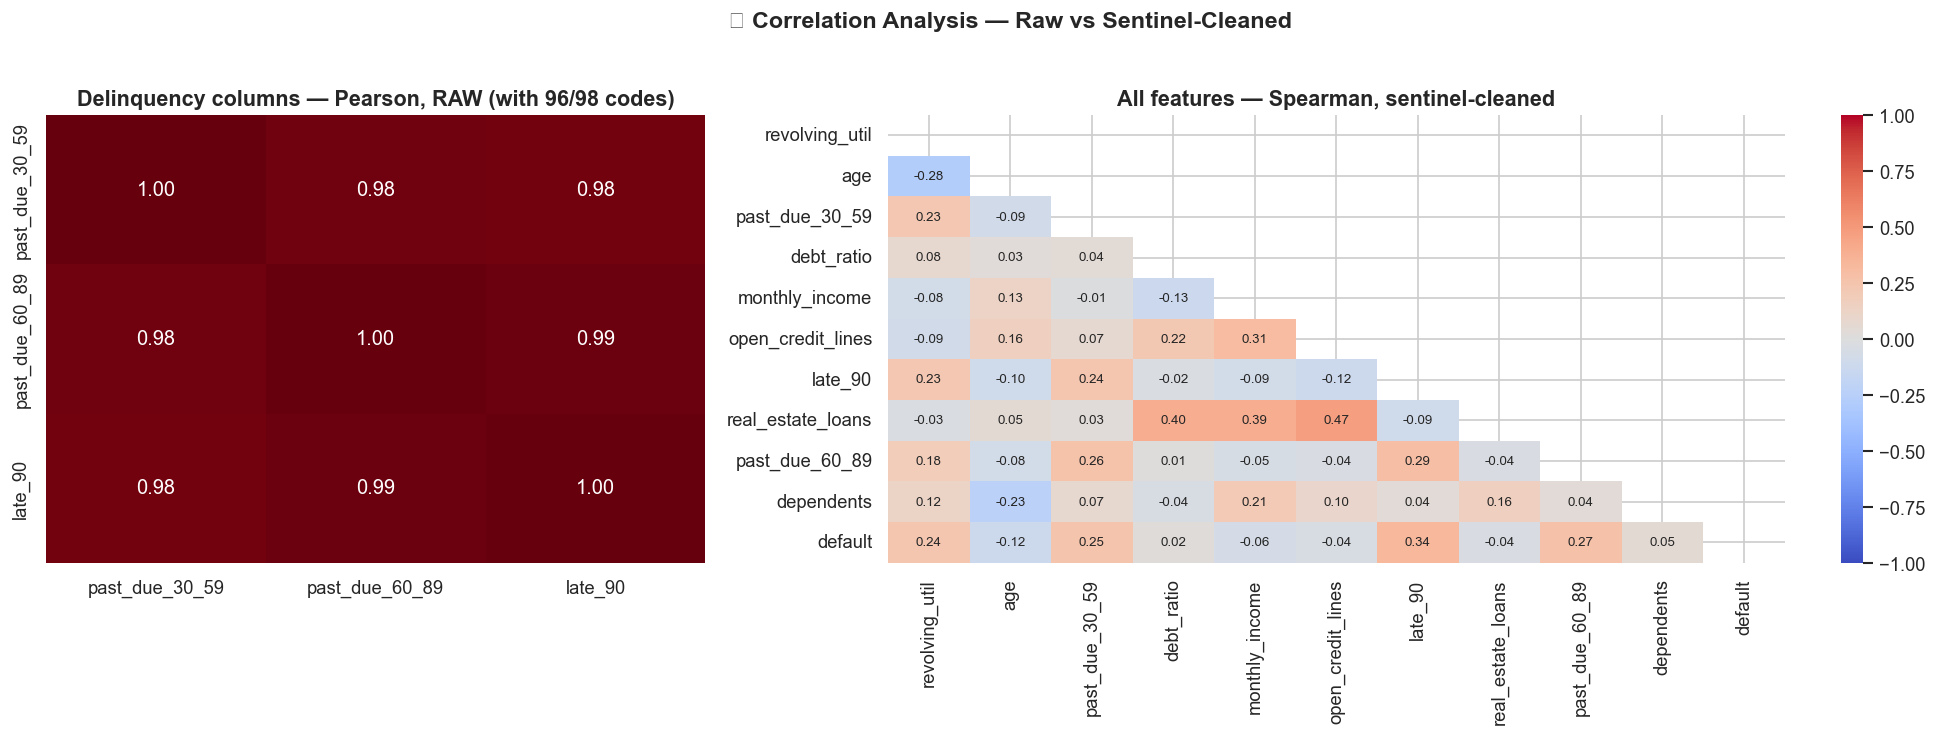

Delinquency Pearson correlation AFTER sentinel removal:


,past_due_30_59,past_due_60_89,late_90
past_due_30_59,1.000000,0.305764,0.218267
past_due_60_89,0.305764,1.000000,0.293997
late_90,0.218267,0.293997,1.000000


Spearman correlation with target:


,spearman_vs_default
late_90,0.335513
past_due_60_89,0.267014
past_due_30_59,0.250192
revolving_util,0.241242
age,-0.118871
monthly_income,-0.064861
dependents,0.047031
open_credit_lines,-0.041289
real_estate_loans,-0.035468
debt_ratio,0.016911


In [41]:
fig, ax = plt.subplots(1, 2, figsize=(17, 6), gridspec_kw={"width_ratios": [1, 1.7]})

raw_corr = train[DELINQ].corr(method="pearson")
sns.heatmap(raw_corr, annot=True, fmt=".2f", cmap="Reds", vmin=0, vmax=1, ax=ax[0], cbar=False)
ax[0].set_title("Delinquency columns — Pearson, RAW (with 96/98 codes)")

clean = mask_sentinels(train)
sp = clean[FEATURES + [TARGET]].corr(method="spearman")
mask = np.triu(np.ones_like(sp, dtype=bool))
sns.heatmap(sp, mask=mask, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1, ax=ax[1], annot_kws={"size": 8})
ax[1].set_title("All features — Spearman, sentinel-cleaned")
plt.suptitle("🔗 Correlation Analysis — Raw vs Sentinel-Cleaned", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout(); plt.show()

print("Delinquency Pearson correlation AFTER sentinel removal:")
display(clean[DELINQ].corr(method="pearson"))
print("Spearman correlation with target:")
display(sp[TARGET].drop(TARGET).sort_values(key=abs, ascending=False).to_frame("spearman_vs_default"))

📌 **Observation:**

- Left panel (raw Pearson): the three delinquency columns look almost identical — **0.98 / 0.98 / 0.99**. After removing the 96 / 98 rows the same correlations fall to **0.22–0.31** (30–59 vs 60–89: 0.31; 60–89 vs 90+: 0.29; 30–59 vs 90+: 0.22). The near-perfect redundancy was produced by 170 sentinel rows; the counters are distinct signals.
- Right panel (Spearman, cleaned): correlation with the target is led by **`late_90` (0.34)**, `past_due_60_89` (0.27), `past_due_30_59` (0.25) and `revolving_util` (0.24); then `age` (−0.12), `monthly_income` (−0.06), `dependents` (+0.05), `open_credit_lines` (−0.04), `real_estate_loans` (−0.04) and `debt_ratio` (0.02).
- The only noticeable feature-to-feature relationships are `real_estate_loans` with `open_credit_lines` (0.47), `debt_ratio` (0.40) and `monthly_income` (0.39), `open_credit_lines` with income (0.31), and `revolving_util` with `age` (−0.28).

💡 **Pipeline decision:**

- Do **not** drop any delinquency column on the basis of the raw correlation — that conclusion would have been an artefact. Build aggregates (`total_delinq`, `severity_score`) and keep the originals for tree models.
- Compute correlation, IV and VIF on **sentinel-cleaned data only** (enforced in the feature-selection step).
- Use Spearman screening as a first filter only: `debt_ratio` has a rank correlation of just 0.02 with the target but is non-monotonic (Step 13), so it cannot be discarded on correlation alone.

---
## Step 17 — Predictive power: Weight of Evidence & Information Value
---
**Why:** **Information Value (IV)** is the industry-standard, model-agnostic ranking of a feature's ability to separate good from bad customers, and **WoE** shows the *shape* of that relationship. Together they are the backbone of scorecard development and feature selection in banks, and they work on a rare-event target.  

**Business insight:** IV tells the credit-policy committee which data sources are worth paying for and which add little; WoE patterns document that the model's logic is sensible and monotonic — a regulatory expectation for explainable credit decisions.

*IV rule of thumb:* < 0.02 useless · 0.02–0.1 weak · 0.1–0.3 medium · 0.3–0.5 strong · > 0.5 suspicious (check leakage).

,feature,IV,strength
0,revolving_util,1.126002,suspicious
1,past_due_30_59,0.473120,strong
2,age,0.263371,medium
3,debt_ratio,0.076010,weak
4,open_credit_lines,0.072892,weak
5,monthly_income,0.072529,weak
6,late_90,0.040788,weak
7,past_due_60_89,0.040788,weak
8,dependents,0.026896,weak
9,real_estate_loans,0.010733,useless


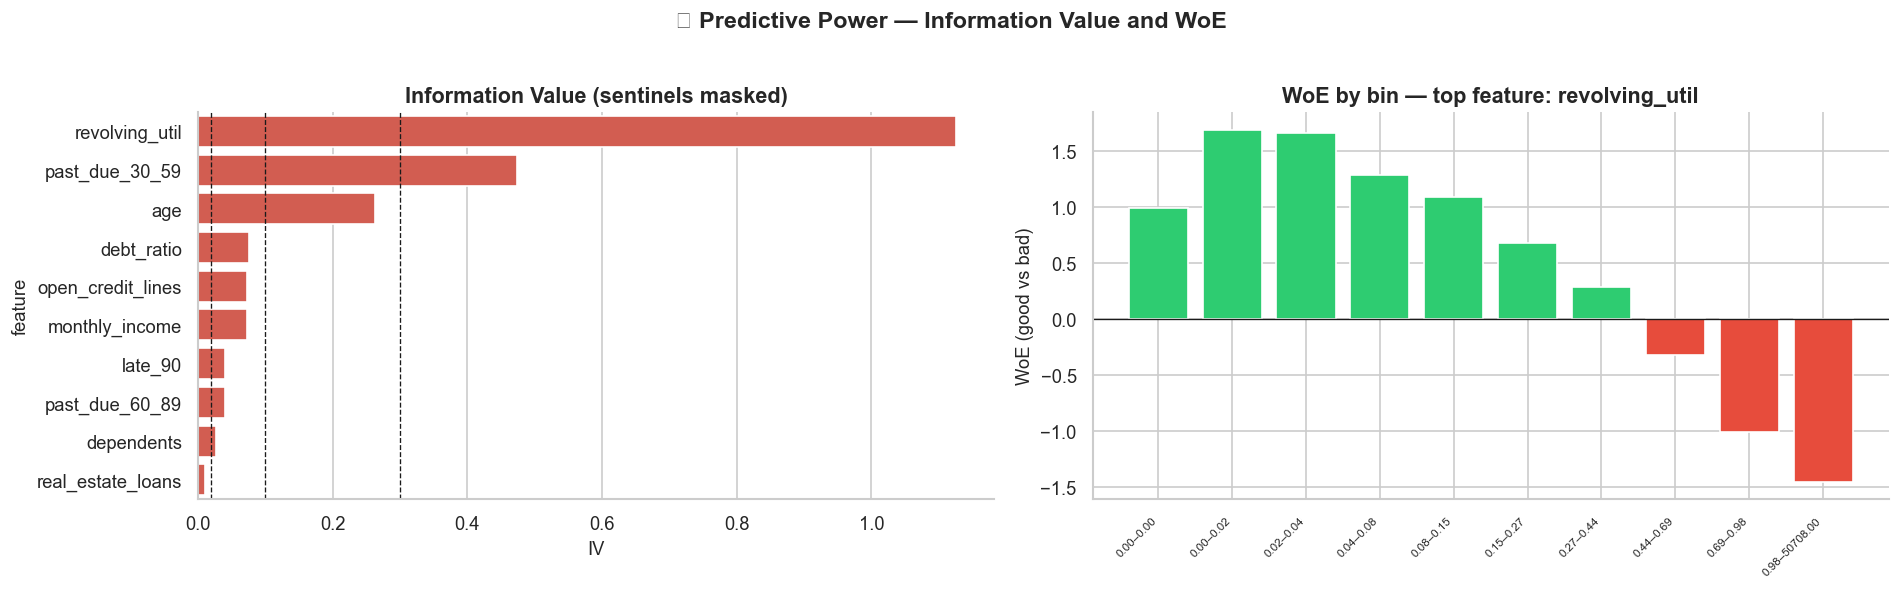

In [42]:
def information_value(d, col, bins=10):
    x = d[[col, TARGET]].copy()
    x["bin"] = pd.qcut(x[col], q=bins, labels=False, duplicates="drop")
    x["bin"] = x["bin"].fillna(-1).astype(int)          # -1 = missing bucket
    g = x.groupby("bin").agg(lo=(col, "min"), hi=(col, "max"), n=(TARGET, "size"), bad=(TARGET, "sum"))
    g["good"] = g["n"] - g["bad"]
    k = len(g)
    g["dist_bad"] = (g["bad"] + 0.5) / (g["bad"].sum() + 0.5 * k)      # Laplace smoothing
    g["dist_good"] = (g["good"] + 0.5) / (g["good"].sum() + 0.5 * k)
    g["woe"] = np.log(g["dist_good"] / g["dist_bad"])
    g["iv"] = (g["dist_good"] - g["dist_bad"]) * g["woe"]
    return g, g["iv"].sum()

clean = mask_sentinels(train)
iv_rows, woe_tables = [], {}
for c in FEATURES:
    g, iv = information_value(clean, c)
    iv_rows.append((c, iv)); woe_tables[c] = g
iv_df = pd.DataFrame(iv_rows, columns=["feature", "IV"]).sort_values("IV", ascending=False).reset_index(drop=True)
iv_df["strength"] = pd.cut(iv_df["IV"], [-1, .02, .1, .3, .5, 99], labels=["useless", "weak", "medium", "strong", "suspicious"])
display(iv_df)

fig, ax = plt.subplots(1, 2, figsize=(16, 4.8))
sns.barplot(data=iv_df, y="feature", x="IV", color=PALETTE["bad"], ax=ax[0])
for x_ in (0.02, 0.1, 0.3): ax[0].axvline(x_, ls="--", c="k", lw=0.8)
ax[0].set_title("Information Value (sentinels masked)")

top = iv_df["feature"].iloc[0]
g = woe_tables[top]
ax[1].bar(range(len(g)), g["woe"], color=np.where(g["woe"] >= 0, PALETTE["good"], PALETTE["bad"]))
ax[1].set_xticks(range(len(g))); ax[1].set_xticklabels([f"{lo:.2f}–{hi:.2f}" for lo, hi in zip(g["lo"], g["hi"])], rotation=45, ha="right", fontsize=7)
ax[1].axhline(0, c="k", lw=0.8); ax[1].set_title(f"WoE by bin — top feature: {top}"); ax[1].set_ylabel("WoE (good vs bad)")
plt.suptitle("⭐ Predictive Power — Information Value and WoE", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout(); plt.show()

📌 **Observation:**

- IV ranking: **`revolving_util` 1.126**, **`past_due_30_59` 0.473** (strong), **`age` 0.263** (medium), then `debt_ratio` 0.076, `open_credit_lines` 0.073, `monthly_income` 0.073 (weak), `late_90` and `past_due_60_89` 0.041, `dependents` 0.027 and `real_estate_loans` 0.011 (useless).
- WoE plot for `revolving_util`: decile 1 (exactly 0.00) has WoE ≈ +1.0, decile 2 (0.00–0.02) peaks at ≈ **+1.7**, then WoE falls monotonically to **−1.45 for the top decile (0.98–50,708)**. Customers with utilisation of exactly zero are a little riskier than those using 1–2% of their limit (unused or inactive accounts).
- An IV of 1.126 is above the usual 0.5 "suspicious" line, but the pattern (a smooth monotonic gradient over a variable that is known at application time) points to a genuinely dominant feature rather than leakage.
- ⚠️ **`late_90` and `past_due_60_89` have exactly the same IV (0.040788)** although Step 12 shows these are the most severe features (default rate 5% → 34% → 50%) and Step 16 gives `late_90` the highest target correlation. This is a **binning artefact**: more than 90% of rows are 0, so `qcut(q=10)` collapses each column into a single bin and the only IV left comes from the 170-row "Missing" bucket created by the sentinel masking — identical for both columns.

💡 **Pipeline decision:**

- Keep IV ≥ 0.02 as the selection rule, but **compute IV for count features with explicit bins** (0 / 1 / 2 / 3+) instead of quantiles; until that is done, the IV of `late_90`, `past_due_60_89` and `past_due_30_59` understates their true power and must not be used to drop them.
- The scorecard branch uses WoE-binned variables with monotonic bins; the GBM champion uses cleaned raw values with monotonic constraints on utilisation and delinquency.
- Treat `revolving_util` (IV > 1) as the primary risk driver: its distribution and caps go under **PSI monitoring**, and WoE tables are exported as artefacts for the model-risk report.

---
## Step 18 — Engineered features: do the decisions from Steps 4–15 pay off?
---
**Why:** Feature engineering should be **validated, not assumed**. Here we apply every cleaning/engineering rule decided so far in one reusable function and compare the IV of the engineered features with the originals — a quick, objective test of lift.  

**Business insight:** Affordability and severity features encode how underwriters actually think ("how many serious late events?", "how much of income is committed to debt?", "how many people depend on this income?"), and are usually more explainable to regulators than raw bureau fields.

,feature,IV,type
8,severity_score,1.226520,engineered
0,revolving_util,1.126002,original
7,total_delinq,0.997283,engineered
2,past_due_30_59,0.425799,original
6,age,0.263380,original
10,income_per_dependent,0.095987,engineered
5,monthly_income,0.072529,original
11,log_income,0.072529,engineered
4,debt_ratio,0.066105,original
9,monthly_debt_payment,0.037787,engineered


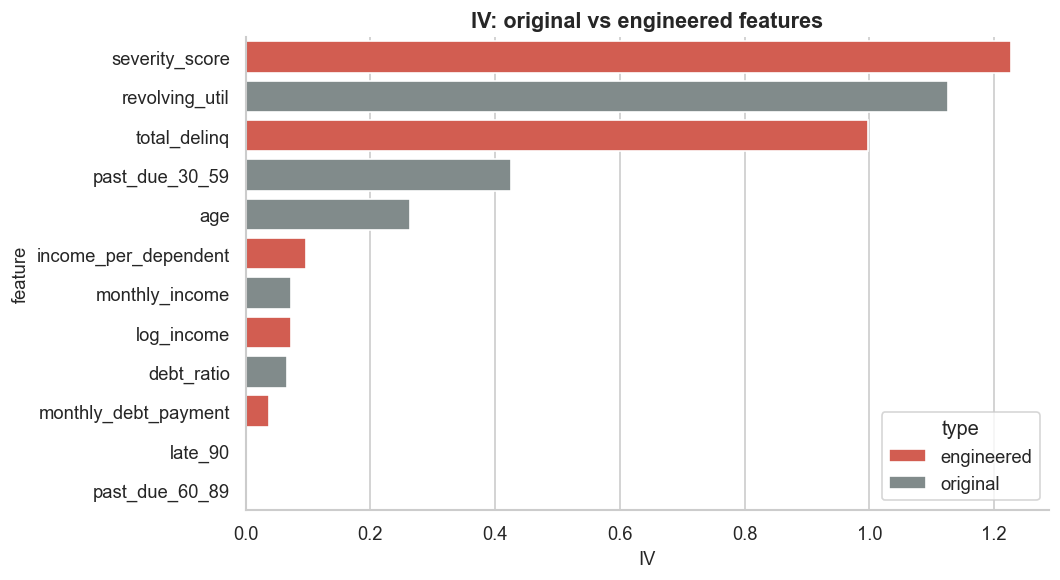

{0: 0.0662, 1: 0.6294}
{0: 0.0699, 1: 0.0551}
{0: 0.0602, 1: 0.3662}


In [43]:
CAPS = {   # learned on TRAIN only
    "revolving_util": float(train["revolving_util"].quantile(0.99)),
    "debt_ratio": float(train.loc[train["monthly_income"].notna(), "debt_ratio"].quantile(0.99)),
    "monthly_income": float(train["monthly_income"].quantile(0.995)),
}
MEDIANS = {"age": float(train.loc[train["age"] >= 18, "age"].median()),
           "monthly_income": float(train["monthly_income"].median()),
           "dependents": 0.0}

def engineer(d):
    d = d.copy()
    # Step 9 — sentinel codes
    d["delinq_sentinel_flag"] = (d[DELINQ] >= 96).any(axis=1).astype(int)
    d[DELINQ] = d[DELINQ].where(d[DELINQ] < 96).fillna(0)
    # Step 10 — impossible ages
    d["age"] = d["age"].where(d["age"] >= 18).fillna(MEDIANS["age"])
    # Step 4 — missing flags
    d["income_missing"] = d["monthly_income"].isna().astype(int)
    d["dependents_missing"] = d["dependents"].isna().astype(int)
    # Step 13 — invalid DTI when income missing
    d.loc[d["income_missing"] == 1, "debt_ratio"] = np.nan
    # Step 11 — utilisation
    d["over_limit_flag"] = (d["revolving_util"] > 1).astype(int)
    d["revolving_util"] = d["revolving_util"].clip(upper=CAPS["revolving_util"])
    # Step 12 — delinquency aggregates
    d["total_delinq"] = d[DELINQ].sum(axis=1)
    d["severity_score"] = d["past_due_30_59"] + 2 * d["past_due_60_89"] + 3 * d["late_90"]
    d["any_delinq"] = (d["total_delinq"] > 0).astype(int)
    # Step 13/14 — affordability
    d["monthly_debt_payment"] = d["debt_ratio"] * d["monthly_income"]
    d["income_per_dependent"] = d["monthly_income"] / (d["dependents"].fillna(0) + 1)
    d["log_income"] = np.log1p(d["monthly_income"].clip(upper=CAPS["monthly_income"]))
    d["debt_ratio"] = d["debt_ratio"].clip(upper=CAPS["debt_ratio"])
    d["dependents"] = d["dependents"].fillna(MEDIANS["dependents"])
    return d

eng = engineer(train)
NEW = ["total_delinq", "severity_score", "monthly_debt_payment", "income_per_dependent", "log_income"]
rows = [(c, information_value(eng, c)[1], "original") for c in ["revolving_util", "late_90", "past_due_30_59", "past_due_60_89", "debt_ratio", "monthly_income", "age"]]
rows += [(c, information_value(eng, c)[1], "engineered") for c in NEW]
cmp = pd.DataFrame(rows, columns=["feature", "IV", "type"]).sort_values("IV", ascending=False)
display(cmp)

plt.figure(figsize=(9, 5))
sns.barplot(data=cmp, y="feature", x="IV", hue="type", palette={"original": PALETTE["neutral"], "engineered": PALETTE["bad"]}, dodge=False)
plt.title("IV: original vs engineered features"); plt.tight_layout(); plt.show()

flags = eng.groupby("delinq_sentinel_flag")[TARGET].mean(), eng.groupby("income_missing")[TARGET].mean(), eng.groupby("over_limit_flag")[TARGET].mean()
for f in flags: print(f.round(4).to_dict())

📌 **Observation:**

- **`severity_score` has the highest IV of all features (1.227)** — above `revolving_util` (1.126) — and **`total_delinq` scores 0.997**, versus 0.426 for the best single counter (`past_due_30_59`). Aggregating the three counters concentrates signal that was spread across them.
- `income_per_dependent` (IV **0.096**) beats raw `monthly_income` (0.073) by about 32%. `log_income` has the same IV as `monthly_income` (0.0725) — expected, because quantile bins ignore monotonic transforms.
- **`monthly_debt_payment` (IV 0.038) is *weaker* than the original `debt_ratio` (0.066)** — the engineered affordability feature did not help.
- `late_90` and `past_due_60_89` show IV 0.000 after cleaning — the single-bin artefact explained in Step 17, not a lack of signal.
- Flag behaviour: **`delinq_sentinel_flag` = 1 → 62.9% default (vs 6.6%)**, **`over_limit_flag` = 1 → 36.6% (vs 6.0%)**, and `income_missing` = 1 → 5.5% (vs 7.0%) — each flag isolates a segment with very different risk.

💡 **Pipeline decision:**

- **Adopt:** `severity_score`, `total_delinq`, `any_delinq`, `over_limit_flag`, `delinq_sentinel_flag`, `income_missing`; add `income_per_dependent` as a low-priority feature.
- ⚠️ **Revise:** `monthly_debt_payment` is not supported by the IV evidence — keep it as an optional candidate for the model stage only, and remove it from the default `feature_adopt` list in the decision log.
- `log_income` is a transform for the linear branch only, with no predictive gain.
- `CAPS` (utilisation 1.092, debt ratio 633.5, income $35,000) and the medians are **fitted on the training split only** and serialised with the model for train / serve parity.

---
## Step 19 — Multicollinearity check (VIF) on the engineered feature set
---
**Why:** Variance Inflation Factor quantifies how much a coefficient's variance is inflated by linear dependence on the other predictors. It is the formal check that follows the correlation heatmap, applied to the *final* candidate features.  

**Business insight:** If two inputs encode the same information, the regression coefficients flip signs or explode, and the **adverse-action reason codes** shown to a declined applicant become unreliable. Stable, explainable coefficients are a compliance requirement for the logistic scorecard.

,VIF (originals only),VIF (with aggregates)
revolving_util,1.22,1.220000e+00
age,1.16,1.160000e+00
debt_ratio,2.27,2.270000e+00
log_income,2.40,2.400000e+00
open_credit_lines,1.31,1.310000e+00
real_estate_loans,1.30,1.300000e+00
dependents,1.10,1.100000e+00
past_due_30_59,1.18,1.057896e+06
past_due_60_89,1.18,1.000800e+15
late_90,1.16,1.000800e+15


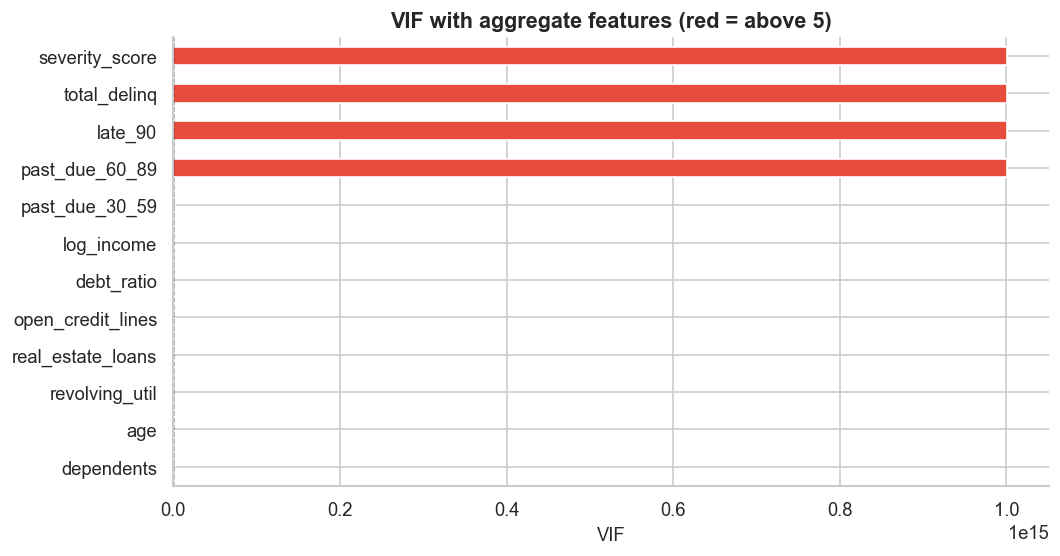

In [44]:
vif_cols = ["revolving_util", "age", "debt_ratio", "log_income", "open_credit_lines", "real_estate_loans",
            "dependents", "past_due_30_59", "past_due_60_89", "late_90", "total_delinq", "severity_score"]
X = eng[vif_cols].copy()
X = X.fillna(X.median())

def vif_table(cols):
    Z = add_constant(X[cols])
    return pd.Series([variance_inflation_factor(Z.values, i) for i in range(1, Z.shape[1])], index=cols, name="VIF")

full = vif_table(vif_cols)
lean = vif_table([c for c in vif_cols if c not in ("total_delinq", "severity_score")])   # originals only

out = pd.concat([lean.rename("VIF (originals only)"), full.rename("VIF (with aggregates)")], axis=1)
display(out.round(2))

fig, ax = plt.subplots(figsize=(9, 4.8))
full.sort_values().plot.barh(color=np.where(full.sort_values() > 5, PALETTE["bad"], PALETTE["good"]), ax=ax)
ax.axvline(5, ls="--", c="k", lw=0.8); ax.axvline(10, ls="--", c="k", lw=0.8)
ax.set_title("VIF with aggregate features (red = above 5)"); ax.set_xlabel("VIF")
plt.tight_layout(); plt.show()

📌 **Observation:**

- With the original features only (after sentinel cleaning) **every VIF is between 1.10 and 2.40** — `log_income` 2.40 and `debt_ratio` 2.27 are the highest; the three delinquency counters sit at 1.16–1.18. There is no multicollinearity problem in the cleaned raw data, which confirms Step 16.
- Adding the aggregates changes the picture completely: `total_delinq`, `severity_score`, `late_90` and `past_due_60_89` all show a VIF of about **1×10¹⁵** and `past_due_30_59` **1.06×10⁶**. This is exact linear dependence (`total_delinq` = sum of the three counters; `severity_score` = 1·a + 2·b + 3·c), and statsmodels raised `SingularMatrixWarning` (rank-deficient design matrix).

💡 **Pipeline decision:**

- **Scorecard / logistic branch:** use *either* the three components *or* the aggregates (`severity_score`) — never both. Enforce it in `feature_sets.yaml`; with both present the regression is not identifiable.
- **GBM branch:** both can coexist (trees tolerate collinearity), but SHAP values are grouped so importance is not split across redundant columns.
- Add a **VIF < 5 gate** to the automated feature-selection step for the linear model.

---
## Step 20 — Class Imbalance Handling Preview
---
**Why:** Step 7 said *that* the data is imbalanced; this step tests *which remedy matters*. We compare three strategies on the same engineered features and the same validation split: no correction (baseline), `class_weight="balanced"`, and SMOTE oversampling applied to the training part only. Ranking metrics (ROC-AUC, PR-AUC) show whether the remedy changes discrimination; the **Brier score** shows whether it damages probability quality.  

**Business insight:** A credit model's output is a Probability of Default used for pricing, provisioning and cut-off setting. A remedy that improves recall but inflates every probability makes the bank's expected-loss estimates wrong — even if the AUC looks the same.

,ROC-AUC,PR-AUC,Brier,mean predicted PD
Baseline (no correction),0.8520,0.3842,0.0506,0.0677
class_weight='balanced',0.8577,0.3908,0.1450,0.3391
SMOTE (train only),0.8487,0.3701,0.1407,0.3184


Actual validation default rate: 0.0670


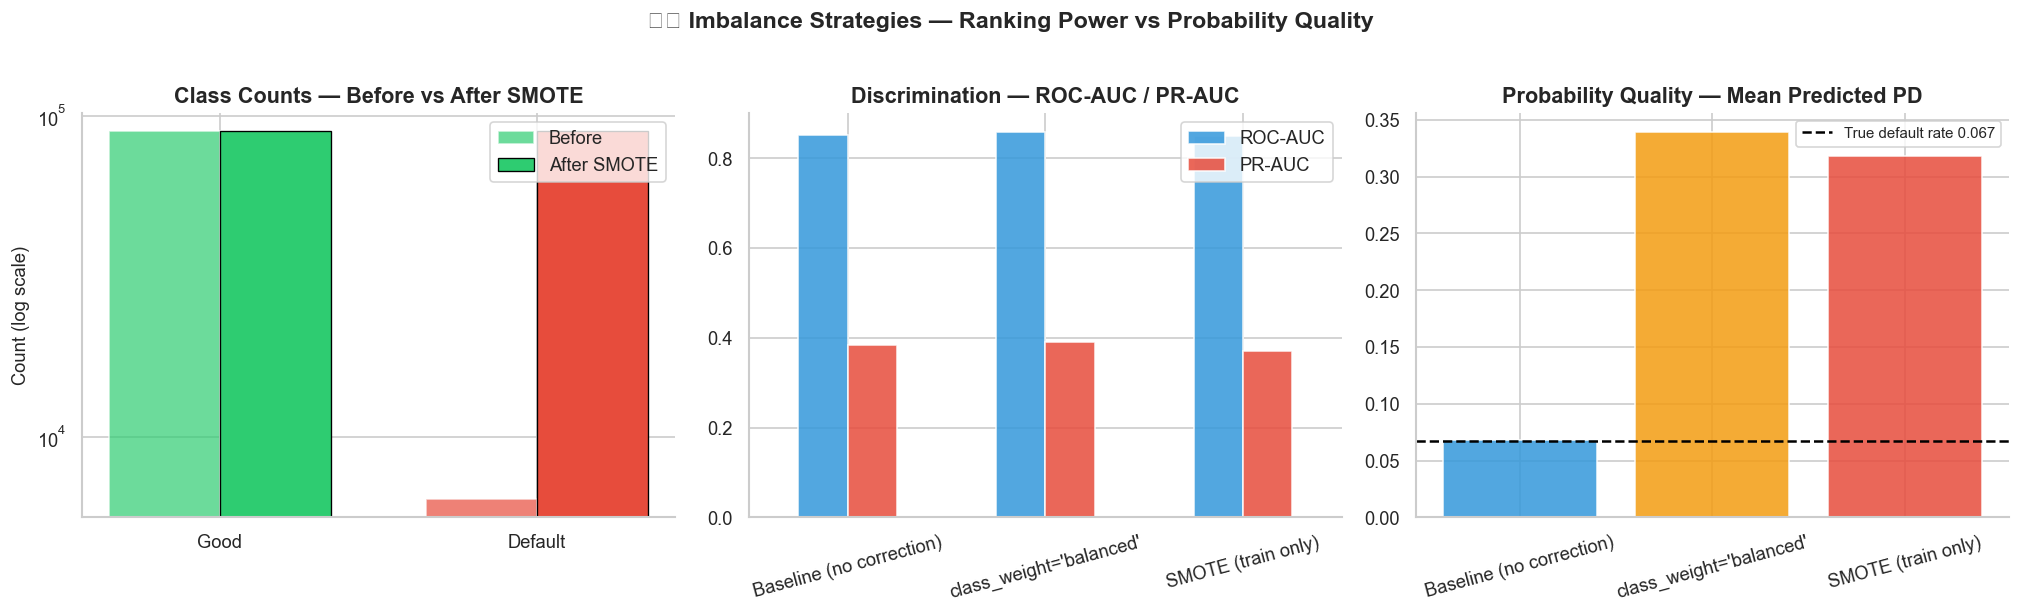

In [45]:
model_cols = ["revolving_util", "age", "debt_ratio", "log_income", "open_credit_lines", "real_estate_loans",
              "dependents", "total_delinq", "severity_score", "monthly_debt_payment",
              "over_limit_flag", "delinq_sentinel_flag", "income_missing", "dependents_missing"]

X = eng[model_cols].copy()
X = X.fillna(X.median())
y = eng[TARGET]

# validation split INSIDE the training data (the hold-out stays untouched)
X_tr, X_val, y_tr, y_val = train_test_split(X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)

def fit_eval(Xa, ya, class_weight=None):
    pipe = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, class_weight=class_weight))
    pipe.fit(Xa, ya)
    p = pipe.predict_proba(X_val)[:, 1]
    return {"ROC-AUC": roc_auc_score(y_val, p), "PR-AUC": average_precision_score(y_val, p),
            "Brier": brier_score_loss(y_val, p), "mean predicted PD": p.mean()}

results = {"Baseline (no correction)": fit_eval(X_tr, y_tr),
           "class_weight='balanced'":  fit_eval(X_tr, y_tr, class_weight="balanced")}

if SMOTE is not None:
    X_sm, y_sm = SMOTE(random_state=RANDOM_STATE).fit_resample(X_tr, y_tr)
    results["SMOTE (train only)"] = fit_eval(X_sm, y_sm)
    before, after = y_tr.value_counts().sort_index(), pd.Series(y_sm).value_counts().sort_index()
else:
    before, after = y_tr.value_counts().sort_index(), None
    print("⚠️ imbalanced-learn not installed — SMOTE row skipped")

res = pd.DataFrame(results).T
display(res.round(4))
print(f"Actual validation default rate: {y_val.mean():.4f}")

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

# class counts before / after
x, w = np.arange(2), 0.35
axes[0].bar(x - w/2, before.values, w, color=[GOOD_COLOR, BAD_COLOR], alpha=0.7, label="Before")
if after is not None:
    axes[0].bar(x + w/2, after.values, w, color=[GOOD_COLOR, BAD_COLOR], alpha=1.0, edgecolor="black", linewidth=0.8, label="After SMOTE")
axes[0].set_xticks(x); axes[0].set_xticklabels(["Good", "Default"]); axes[0].set_yscale("log")
axes[0].set_title("Class Counts — Before vs After SMOTE"); axes[0].set_ylabel("Count (log scale)"); axes[0].legend()

# ranking metrics
res[["ROC-AUC", "PR-AUC"]].plot.bar(ax=axes[1], color=[ACCENT_COLOR, BAD_COLOR], alpha=0.85, edgecolor="white")
axes[1].set_title("Discrimination — ROC-AUC / PR-AUC"); axes[1].tick_params(axis="x", rotation=15); axes[1].set_xlabel("")

# probability quality
bars = axes[2].bar(res.index, res["mean predicted PD"], color=[ACCENT_COLOR, WARN_COLOR, BAD_COLOR][:len(res)], alpha=0.85)
axes[2].axhline(y_val.mean(), color="black", linestyle="--", linewidth=1.5, label=f"True default rate {y_val.mean():.3f}")
axes[2].set_title("Probability Quality — Mean Predicted PD"); axes[2].tick_params(axis="x", rotation=15); axes[2].legend(fontsize=9)

plt.suptitle("⚖️ Imbalance Strategies — Ranking Power vs Probability Quality",
             fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

📌 **Observation:**

| Strategy | ROC-AUC | PR-AUC | Brier | Mean predicted PD |
|---|---|---|---|---|
| Baseline (no correction) | 0.8520 | 0.3842 | **0.0506** | **0.0677** |
| `class_weight='balanced'` | **0.8577** | **0.3908** | 0.1450 | 0.3391 |
| SMOTE (train only) | 0.8487 | 0.3701 | 0.1407 | 0.3184 |

- Ranking power barely moves: ROC-AUC ranges over only 0.849–0.858, with `class_weight` slightly best (+0.006) and SMOTE slightly worst (−0.003 vs baseline; PR-AUC 0.370 vs 0.384).
- Probability quality is where the strategies differ: the actual default rate is 0.067 and the baseline predicts 0.068, but `class_weight` and SMOTE predict **0.339 and 0.318 — about 5× too high** — and the Brier score almost **triples** (0.051 → 0.145 / 0.141).
- Left panel: SMOTE lifts the minority class from ~8,000 to ~89,000 rows, a roughly 11× synthetic expansion.

💡 **Pipeline decision:**

- Use `class_weight` / `scale_pos_weight` **inside** the model (best ranking, no synthetic rows) and **recalibrate afterwards** (isotonic / Platt) on untouched data — this is exactly what `03_unified_risk_analysis` does (mean score 0.324 → 0.069 after calibration).
- SMOTE stays a challenger only: it is applied inside an `imblearn` Pipeline so it sees training folds exclusively, and it is never used to produce the data on which calibration or thresholds are chosen.

---
## Step 21 — Feature Scaling Preview
---
**Why:** Distance- and gradient-based models (Logistic Regression / WoE scorecard, KNN, SGD) need features on comparable scales — otherwise a feature with range [0, 50,000] dominates one in [0, 1]. Tree-based models (XGBoost, LightGBM, ExtraTrees) are invariant to monotonic scaling. We test which engineered features are still skewed after cleaning and show the effect of a Yeo-Johnson power transform plus standardisation on the worst offenders.  

**Business insight:** One preprocessor for every model is a common mistake. A tree model trained on scaled features performs the same, but a linear scorecard trained on skewed, unscaled inputs performs poorly and produces unstable coefficients — which breaks explainability. A dual-preprocessor design matches each model family to its optimal input.

Continuous features requiring PowerTransform (|skew| > 1.0) : 8  → ['monthly_debt_payment', 'debt_ratio', 'severity_score', 'log_income', 'total_delinq', 'real_estate_loans', 'dependents', 'open_credit_lines']
Continuous features requiring only StandardScaler           : 2


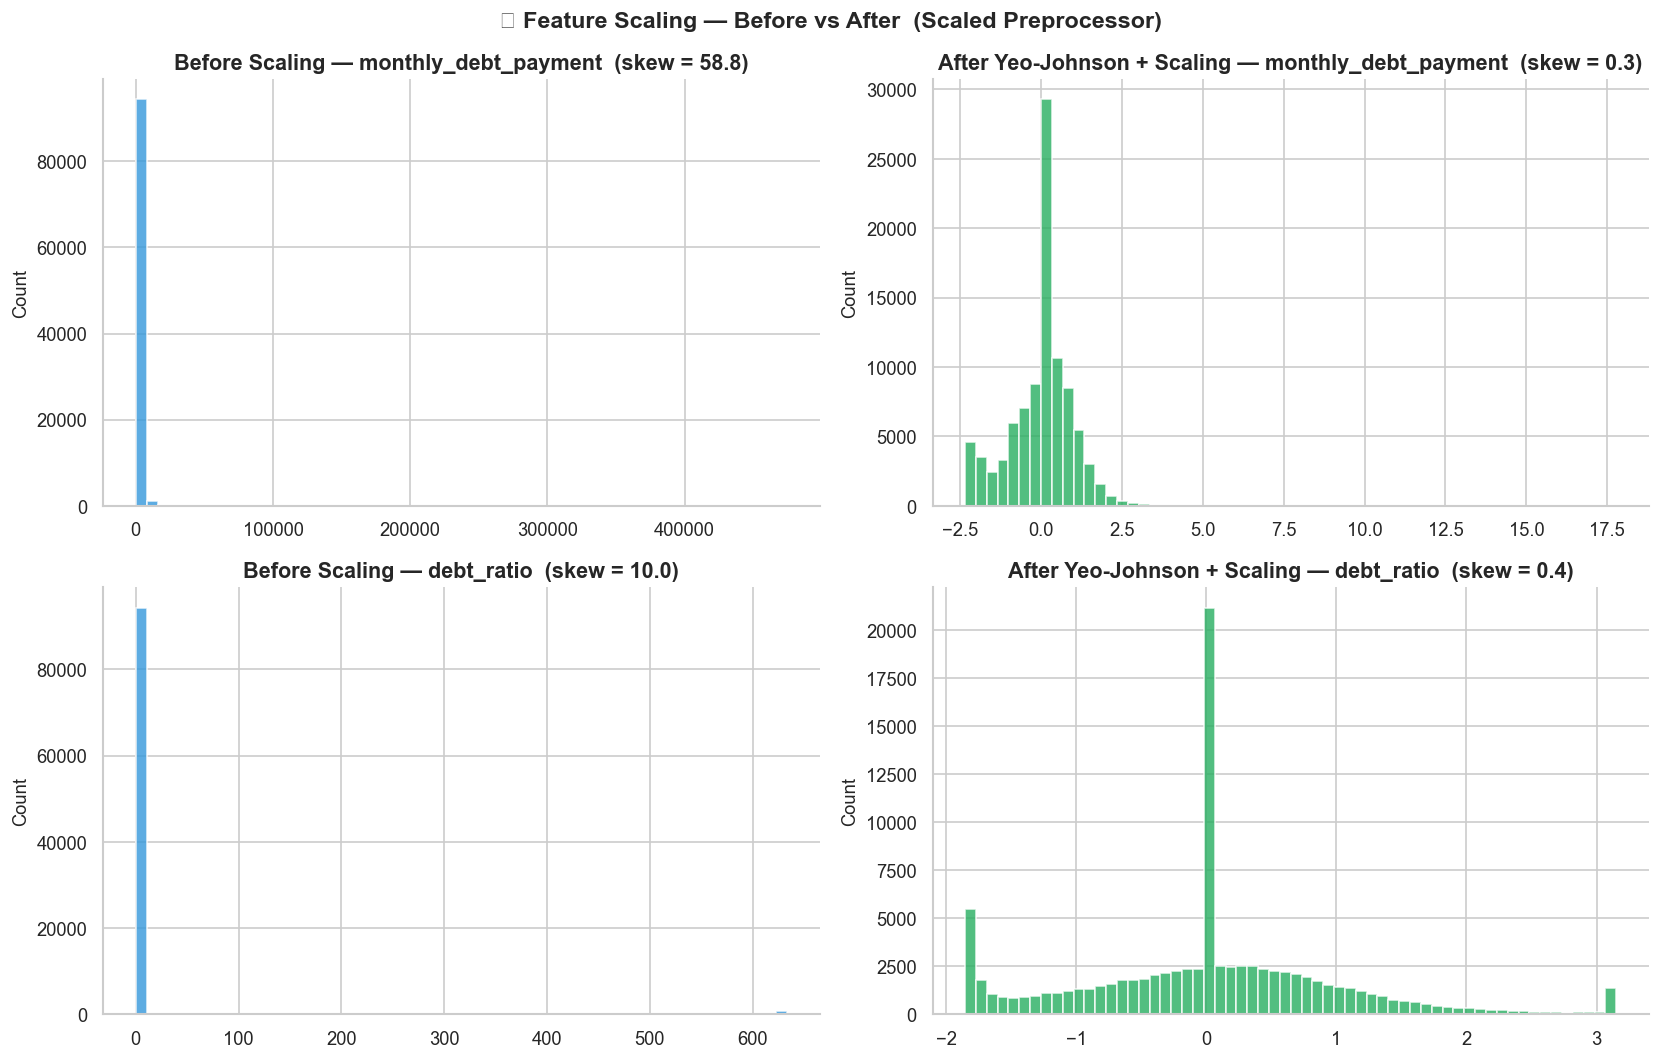


Dual-Preprocessor Architecture:
┌─────────────────────────────────────────────────────────────────────┐
│  pre_scaled   → Winsoriser → PowerTransformer → StandardScaler      │
│                → Logistic Regression / WoE scorecard, SGD, KNN      │
│  pre_unscaled → Winsoriser → passthrough                            │
│                → XGBoost, LightGBM, ExtraTrees                      │
└─────────────────────────────────────────────────────────────────────┘


In [46]:
sample_s = X_tr.copy()

# binary flags are excluded — a power transform on a 0/1 column is meaningless
cont_cols   = [c for c in sample_s.columns if sample_s[c].nunique() > 2]
skew        = sample_s[cont_cols].skew().abs().sort_values(ascending=False)
skewed_cols = skew[skew > 1.0].index.tolist()
normal_cols = [c for c in cont_cols if c not in skewed_cols]

print(f"Continuous features requiring PowerTransform (|skew| > 1.0) : {len(skewed_cols)}  → {skewed_cols}")
print(f"Continuous features requiring only StandardScaler           : {len(normal_cols)}")

pt, scaler = PowerTransformer(method="yeo-johnson", standardize=False), StandardScaler()
sample_scaled = sample_s.copy()
if skewed_cols:
    sample_scaled[skewed_cols] = pt.fit_transform(sample_s[skewed_cols])
sample_scaled[cont_cols] = scaler.fit_transform(sample_scaled[cont_cols])

show_features = skew.index[:2].tolist()
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for i, feat in enumerate(show_features):
    axes[i, 0].hist(sample_s[feat], bins=60, color=ACCENT_COLOR, alpha=0.8, edgecolor="white")
    axes[i, 0].set_title(f"Before Scaling — {feat}  (skew = {sample_s[feat].skew():.1f})"); axes[i, 0].set_ylabel("Count")
    axes[i, 1].hist(sample_scaled[feat], bins=60, color="#27AE60", alpha=0.8, edgecolor="white")
    axes[i, 1].set_title(f"After Yeo-Johnson + Scaling — {feat}  (skew = {sample_scaled[feat].skew():.1f})"); axes[i, 1].set_ylabel("Count")

plt.suptitle("📐 Feature Scaling — Before vs After  (Scaled Preprocessor)", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

print("\nDual-Preprocessor Architecture:")
print("┌─────────────────────────────────────────────────────────────────────┐")
print("│  pre_scaled   → Winsoriser → PowerTransformer → StandardScaler      │")
print("│                → Logistic Regression / WoE scorecard, SGD, KNN      │")
print("│  pre_unscaled → Winsoriser → passthrough                            │")
print("│                → XGBoost, LightGBM, ExtraTrees                      │")
print("└─────────────────────────────────────────────────────────────────────┘")

📌 **Observation:**

- **8 of the 10 continuous features are skewed (|skew| > 1)**: `monthly_debt_payment`, `debt_ratio`, `severity_score`, `log_income`, `total_delinq`, `real_estate_loans`, `dependents`, `open_credit_lines`. Only `revolving_util` and `age` need standardisation alone. `log_income` stays "skewed" even after the log transform, most likely because the zero / one-dollar incomes create a long left tail.
- The plots show the limits of the transform. `monthly_debt_payment` falls from skewness **58.8 to 0.3**, but a tail still reaches ≈ 17 standard deviations and a tall spike sits at the centre (the ~20% of rows that were median-imputed). `debt_ratio` falls from **10.0 to 0.4**, but shows three mass points: the imputed centre spike, a left-edge spike (ratios of zero) and a right-edge spike (values at the 633.5 cap).
- Yeo-Johnson fixes the *shape* of the continuous part but cannot spread out mass points created by imputation, zeros and caps.

💡 **Pipeline decision:**

- `build_preprocessors()` returns two `ColumnTransformer`s: **`pre_scaled`** (Winsoriser → PowerTransformer → StandardScaler) for the linear / WoE scorecard, and **`pre_unscaled`** (Winsoriser → passthrough) for tree models. Every transformer is fitted on training folds only.
- Because the mass points carry information (imputed / zero / capped), the **flags created in Steps 3–13 stay in the feature set** — the model needs them to tell imputed values from observed ones.

---
## Step 22 — Key Insights Summary
---
**Why:** An EDA is only valuable if its conclusions flow into the pipeline. This final step prints the headline facts, then exports the learned thresholds (`CAPS`, `MEDIANS`) and rules to a JSON artefact that the `src/` modules load — so notebook logic and production logic can never diverge.  

**Business insight:** A written, versioned decision log is the audit trail that model-risk management and regulators ask for: *what was observed in the data, what was decided, and why*.

In [47]:
top3 = ", ".join(iv_df["feature"].head(3))
print("=" * 70)
print("  CREDIT RISK PREDICTION — EDA COMPLETE")
print("=" * 70)
print(f"  Dataset rows (after dedup) : {df.shape[0]:>12,}")
print(f"  Train / hold-out rows      : {len(train):>6,} / {len(holdout):,}")
print(f"  Default rate               : {df[TARGET].mean()*100:>11.3f}%")
print(f"  Imbalance ratio            : {(df[TARGET]==0).sum() / (df[TARGET]==1).sum():>10.1f}:1")
print(f"  Top IV features            : {top3}")
print(f"  Primary metrics            : {'ROC-AUC / PR-AUC / KS':>20}")
print(f"  Imbalance fix              : {'class_weight + calibration':>20}")
print(f"  Income handling            : {'median impute + flag':>20}")
print(f"  Engineered features        : {8:>20}")
print("=" * 70)

  CREDIT RISK PREDICTION — EDA COMPLETE
  Dataset rows (after dedup) :      149,391
  Train / hold-out rows      : 119,512 / 29,879
  Default rate               :       6.700%
  Imbalance ratio            :       13.9:1
  Top IV features            : revolving_util, past_due_30_59, age
  Primary metrics            : ROC-AUC / PR-AUC / KS
  Imbalance fix              : class_weight + calibration
  Income handling            : median impute + flag
  Engineered features        :                    8


In [48]:
decision_log = {
    "dataset": "GiveMeSomeCredit/cs-training.csv",
    "split": {"train_rows": int(len(train)), "holdout_rows": int(len(holdout)), "test_size": 0.2,
              "stratify": TARGET, "random_state": RANDOM_STATE},
    "base_default_rate_train": round(float(BASE_RATE), 5),
    "column_rename_map": RENAME,
    "sentinel_codes": {"columns": DELINQ, "codes": [96, 98], "action": "flag + set NaN + impute 0"},
    "rules": {
        "age_min_valid": 18,
        "debt_ratio_when_income_missing": "set NaN",
        "revolving_util_over_limit_flag": "> 1.0",
        "missing_flags": ["income_missing", "dependents_missing"],
    },
    "caps_fit_on_train": CAPS,
    "medians_fit_on_train": MEDIANS,
    "feature_adopt": ["total_delinq", "severity_score", "any_delinq", "monthly_debt_payment",
                      "log_income", "over_limit_flag", "delinq_sentinel_flag", "income_missing"],
    "monotonic_constraints_gbm": {"revolving_util": 1, "past_due_30_59": 1, "past_due_60_89": 1, "late_90": 1,
                                  "total_delinq": 1, "severity_score": 1},
    "iv_ranking": iv_df.set_index("feature")["IV"].round(4).to_dict(),
    "vif_gate": 5,
}
out_path = REPORT_DIR / "credit_eda_decisions.json"
out_path.write_text(json.dumps(decision_log, indent=2))
print(f"Saved → {out_path.resolve()}")
print(json.dumps({k: decision_log[k] for k in ("split", "caps_fit_on_train", "medians_fit_on_train")}, indent=2))

Saved → C:\Users\Narendra Kalam\Data_Science_Capstone_Projects\ai-loan-underwriting-platform\notebooks\reports\credit_eda_decisions.json
{
  "split": {
    "train_rows": 119512,
    "holdout_rows": 29879,
    "test_size": 0.2,
    "stratify": "default",
    "random_state": 42
  },
  "caps_fit_on_train": {
    "revolving_util": 1.09219485026,
    "debt_ratio": 633.539999999979,
    "monthly_income": 35000.0
  },
  "medians_fit_on_train": {
    "age": 52.0,
    "monthly_income": 5400.0,
    "dependents": 0.0
  }
}


📌 **Observation:**

- After de-duplication the file holds **149,391 rows (119,512 train / 29,879 hold-out) with a 6.700% default rate (13.9 : 1)**. The strongest features by IV are `revolving_util`, `past_due_30_59` and `age` (and, among the engineered features, `severity_score`).
- The exported decision log stores the training-only parameters: **caps — utilisation 1.092, debt ratio 633.54, income $35,000; medians — age 52, income $5,400, dependents 0**.
- The data is model-ready after a small, well-defined rule set (de-duplication, sentinel handling, age validation, missingness flags, DTI repair, winsorisation). Three open items remain: the IV binning artefact (Step 17), the DTI cap / zero-income rule (Step 13) and `monthly_debt_payment` (Step 18).

💡 **Pipeline decision:** The next module is `src/features/build_credit_features.py`, which loads `reports/credit_eda_decisions.json` and implements every rule as a tested, deterministic transformer with pytest coverage (sentinel flag, `age < 18`, DTI repair, winsorisation caps). The fitted pipeline is serialised with `joblib` together with the decision log. Modelling plan: **WoE-logistic scorecard** (explainable baseline) vs **LightGBM with monotonic constraints** (champion), judged on ROC-AUC, PR-AUC, KS, calibration and expected loss.

### 📋 EDA-to-Pipeline Decision Map

| # | EDA Finding | Pipeline Decision |
|---|-------------|-------------------|
| 1 | **6.7% default rate (13.9 : 1), 609 duplicate rows removed** | Dedup before split; `StratifiedKFold`; ROC-AUC / PR-AUC / KS; `class_weight` + calibration — not accuracy |
| 2 | **Income missing 19.8% (default 5.6% vs 6.9%), dependents 2.6% (4.6% vs 6.7%)** | Median impute inside the pipeline + `income_missing` / `dependents_missing` flags; never drop rows |
| 3 | **170 rows carry the 96 / 98 code in all three counters — 62.9% default** | `delinq_sentinel_flag`, then NaN + impute 0; never `clip()` |
| 4 | **`age = 0`; default 12.2% (25–29) → 2.3% (70+)** | Impute `age < 18`; age bands for the scorecard; fairness review across age bands |
| 5 | **Utilisation: 1.8% → 39.1% gradient, max 50,708, spike at exactly 1.0** | Winsorise at p99 (1.092); `over_limit_flag` (36.6% default); monotonic +1 |
| 6 | **`debt_ratio` is an amount when income is missing (median 1,197; 95.5% above 1); ratios > 5 with known income default only 3.9%** | NaN when income missing; ⚠️ extend to zero income and lower the cap (633.5 is too high); data-quality ticket |
| 7 | **Raw delinquency correlation 0.98 falls to 0.22–0.31 after cleaning** | Correlation / IV / VIF on sentinel-cleaned data only |
| 8 | **IV: utilisation 1.13, `past_due_30_59` 0.47, age 0.26; `late_90` / `past_due_60_89` collapse to one bin** | ⚠️ Explicit bins (0 / 1 / 2 / 3+) for count features before IV-based selection |
| 9 | **`severity_score` IV 1.23, `total_delinq` 1.00; `monthly_debt_payment` 0.038 < `debt_ratio` 0.066** | Adopt the aggregates and flags; ⚠️ drop `monthly_debt_payment` from the default feature set |
| 10 | **Aggregates + components give VIF ≈ 10¹⁵ (exact collinearity)** | Linear branch: components **or** aggregates, never both; VIF < 5 gate |
| 11 | **`class_weight` / SMOTE leave AUC ≈ 0.85 but inflate mean PD ≈ 5× (Brier ×3)** | `class_weight` in the model + post-hoc calibration; SMOTE only as an in-fold challenger |
| 12 | **8 of 10 continuous features skewed; mass points at imputed / zero / capped values** | `pre_scaled` (Winsor → Yeo-Johnson → Scaler) for linear models, `pre_unscaled` for trees; keep the flags |
| 13 | **Caps and medians must come from training data only** | `CAPS` / `MEDIANS` serialised with the model (train / serve parity) |

---

### 🏗️ Pipeline Flow (EDA → Production)

*(module names are the proposed `src/` layout for the capstone)*

```
Raw CSV (cs-training.csv)
   │
   ▼  validate_input_data()          → column checks, dtype/range checks, dedup, target validation
   ▼  stratified_split()             → 80 / 20 train / hold-out (hold-out untouched until final report)
   ▼  clean_credit_data()            → sentinel flag + NaN, age < 18 → NaN, DTI repair, winsorise (train caps)
   ▼  impute_and_flag()              → median impute (fit on train) + income_missing / dependents_missing
   ▼  build_credit_features()        → total_delinq, severity_score, any_delinq, monthly_debt_payment,
   │                                    log_income, over_limit_flag, delinq_sentinel_flag
   ▼  select_features()              → IV ≥ 0.02, VIF < 5 gate (linear branch)
   ▼  build_preprocessors()          → pre_scaled (Winsor→Power→Scaler / WoE)
   │                                 → pre_unscaled (Winsor→passthrough)
   ▼  tune_models()                  → WoE-Logistic scorecard + XGBoost + LightGBM (monotonic) × PR-AUC
   ▼  calibrate_and_evaluate()       → isotonic / Platt, KS, Gini, PR-AUC, expected-loss threshold
   ▼  decision_engine()              → APPROVE | REVIEW | DECLINE  (combined with the fraud score)
   ▼  Save + Registry                → credit_pd_model_v1.joblib + latest_model.json
   ▼  FastAPI /score                 → real-time inference with identical feature engineering
   ▼  Streamlit dashboard            → monitoring, PSI drift alerts, Champion-Challenger tracking
```

---

*EDA completed by Narendra Kalam — AI Loan Underwriting Platform (Credit Risk Module)*